In [1]:
# En Google Colab, si es necesario:
# !pip -q install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.stats import norm

#Capital Económico y variable de pérdida

# 1. Expected Loss, Unexpected Loss y Capital Económico

Antes de construir el modelo completo de Capital Económico debemos distinguir tres preguntas diferentes:

1. ¿Cuál es la pérdida media esperada de un crédito?
2. ¿Cuánto puede desviarse esa pérdida de su media?
3. ¿Cuánto puede perder una **cartera completa** en un escenario adverso?

Estas preguntas llevan a medidas diferentes:

$$
\boxed{EL}
\qquad
\boxed{UL}
\qquad
\boxed{EC}
$$

y las fórmulas dependen de si estamos analizando:

- un crédito individual;
- una cartera granular;
- o una cartera real con dependencia entre emisores.

## 1.1 Expected Loss: la pérdida media

Para un crédito:

$$
\boxed{
EL=PD\times LGD\times EAD
}
$$

donde:

- $PD$: Probability of Default;
- $LGD$: Loss Given Default;
- $EAD$: Exposure at Default.

Si:

$$
PD=2\%,\qquad LGD=45\%,\qquad EAD=100\,M€
$$

entonces:

$$
EL
=
0.02\times0.45\times100
=
0.9\,M€
$$

La interpretación es:

> Si pudiéramos repetir muchas veces créditos con estas mismas características, la pérdida media sería de 0.9 M€.

La Expected Loss es, por tanto, una **media**, no una predicción de la pérdida que ocurrirá exactamente.

## 1.2 Un único crédito: modelo binomial

Para un único crédito, en la versión más sencilla existen únicamente dos posibles estados:

$$
L=
\begin{cases}
EAD\times LGD & \text{con probabilidad }PD\\
0 & \text{con probabilidad }1-PD
\end{cases}
$$

Podemos escribir:

$$
L=EAD\times LGD\times D
$$

donde:

$$
D\sim Bernoulli(PD)
$$

Sabemos que:

$$
E[D]=PD
$$

y:

$$
Var(D)=PD(1-PD)
$$

Por tanto:

$$
E[L]
=
EAD\times LGD\times PD
$$

y:

$$
Var(L)
=
(EAD\times LGD)^2PD(1-PD)
$$

La desviación estándar de la pérdida es:

$$
\boxed{
UL_{\sigma}
=
\sigma_L
=
EAD\times LGD
\sqrt{PD(1-PD)}
}
$$

In [2]:
import numpy as np

PD=0.02
LGD=0.45
EAD=100_000_000

EL=PD*LGD*EAD
UL_sigma=EAD*LGD*np.sqrt(PD*(1-PD))

print(f"Expected Loss:            €{EL:,.0f}")
print(f"UL como desviación std.: €{UL_sigma:,.0f}")

Expected Loss:            €900,000
UL como desviación std.: €6,300,000


### ¿Qué significa esta Unexpected Loss?

En esta formulación:

$$
\boxed{UL=\sigma_L}
$$

UL significa simplemente:

> **desviación estándar de la distribución de pérdidas.**

No significa todavía:

> “capital necesario para sobrevivir con un 99.9% de confianza”.

Por ejemplo:

$$
EL=0.9M€
$$

y:

$$
UL_{\sigma}=6.3M€
$$

nos dicen:

- dónde está el centro de la distribución;
- cuánto se dispersan las pérdidas alrededor de ese centro.

Pero todavía no hemos escogido ningún nivel de solvencia:

$$
99\%,\quad99.9\%,\quad99.95\%
$$

Por tanto:

$$
\boxed{
UL_{\sigma}\neq EC_{99.9\%}
}
$$

en general.

## 1.3 ¿Qué ocurre si PD y LGD también son inciertas?

Hasta ahora hemos supuesto:

$$
PD=\text{constante}
$$

y:

$$
LGD=\text{constante}
$$

Pero en la realidad ambas variables son estimaciones y pueden variar.

Entonces la incertidumbre total de la pérdida puede descomponerse aproximadamente en:

- incertidumbre sobre la PD;
- incertidumbre sobre la LGD.

Una expresión utilizada en aproximaciones analíticas es:

$$
UL
\approx
EAD
\sqrt{
LGD^2\sigma_{PD}^2
+
PD\,\sigma_{LGD}^2
}
$$

La intuición es:

$$
\boxed{
\text{incertidumbre de pérdida}
=
\text{incertidumbre de default}
+
\text{incertidumbre de severidad}
}
$$

Pero esta fórmula depende de los supuestos concretos adoptados sobre PD, LGD y sus varianzas.

No debe confundirse con la fórmula binomial:

$$
EAD\times LGD\sqrt{PD(1-PD)}
$$

que supone una PD y una LGD fijas y hace aleatorio únicamente el evento de default.

## 1.4 De un crédito a una cartera

Para una cartera:

$$
L=\sum_{i=1}^{N}L_i
$$

y:

$$
EL_{portfolio}
=
\sum_{i=1}^{N}
PD_iLGD_iEAD_i
$$

La Expected Loss sigue siendo fácil de agregar.

Pero la varianza de cartera es:

$$
\boxed{
Var(L)
=
\sum_i Var(L_i)
+
2\sum_{i<j}Cov(L_i,L_j)
}
$$

Por tanto:

$$
\boxed{
UL_{portfolio}
=
\sqrt{Var(L)}
}
$$

La segunda parte es fundamental:

$$
Cov(L_i,L_j)
$$

porque representa la posibilidad de que varias empresas se deterioren o entren en default al mismo tiempo.

### El problema de aplicar la fórmula individual a toda la cartera

Si simplemente calculáramos:

$$
UL_i
=
EAD_iLGD_i\sqrt{PD_i(1-PD_i)}
$$

para cada empresa y sumáramos:

$$
\sum_iUL_i
$$

estaríamos ignorando la diversificación.

Y si calculáramos:

$$
\sqrt{\sum_iUL_i^2}
$$

estaríamos suponiendo independencia.

Pero en crédito:

$$
\boxed{
Default_i\not\perp Default_j
}
$$

porque las empresas comparten:

- ciclo económico;
- tipos de interés;
- condiciones financieras;
- shocks sectoriales.

Por eso, para una cartera:

$$
\boxed{
\text{la PD individual no es suficiente}
}
$$

Necesitamos modelar también:

$$
\boxed{
\text{dependencia entre emisores}
}
$$

## 1.5 Aproximación de cartera: Worst-Case Default Rate

Una forma analítica de aproximar el riesgo de una cartera muy grande y granular consiste en sustituir la PD media por una tasa de default adversa:

$$
WCDR
=
\text{Worst-Case Default Rate}
$$

Entonces:

$$
\text{Pérdida adversa}
=
WCDR\times LGD\times EAD
$$

mientras que:

$$
EL
=
PD\times LGD\times EAD
$$

Por tanto:

$$
\boxed{
UL
=
(WCDR-PD)\times LGD\times EAD
}
$$

La interpretación es inmediata:

$$
\boxed{
UL=
\text{pérdida en escenario adverso}
-
\text{pérdida esperada}
}
$$

## 1.6 ¿De dónde sale el WCDR?

En el modelo de Vasicek suponemos que la situación crediticia de cada deudor depende de:

- un factor sistemático común $Y$;
- un shock idiosincrático $\varepsilon_i$.

$$
X_i
=
\sqrt{\rho}\,Y
+
\sqrt{1-\rho}\,\varepsilon_i
$$

El default ocurre cuando:

$$
X_i<\Phi^{-1}(PD)
$$

Condicionando a un estado adverso del factor sistemático, la PD condicional es:

$$
PD(Y)
=
\Phi
\left(
\frac{
\Phi^{-1}(PD)-\sqrt{\rho}Y
}{
\sqrt{1-\rho}
}
\right)
$$

En un percentil extremo de la economía podemos escribir:

$$
\boxed{
WCDR_\alpha
=
\Phi
\left(
\frac{
\Phi^{-1}(PD)
+
\sqrt{\rho}\Phi^{-1}(\alpha)
}{
\sqrt{1-\rho}
}
\right)
}
$$

Por ejemplo, para:

$$
\alpha=99.9\%
$$

obtenemos la tasa de default correspondiente a un estado extremadamente adverso de la economía.

### Capital bajo la aproximación Vasicek

La pérdida extrema sería:

$$
L_{\alpha}
=
WCDR_\alpha
\times LGD
\times EAD
$$

La Expected Loss:

$$
EL
=
PD\times LGD\times EAD
$$

Por tanto:

$$
\boxed{
EC_\alpha
=
EAD\times LGD
\left[
WCDR_\alpha-PD
\right]
}
$$

o, desarrollando el WCDR:

$$
\boxed{
EC_\alpha
=
EAD\times LGD
\left[
\Phi
\left(
\frac{
\Phi^{-1}(PD)
+
\sqrt{\rho}\Phi^{-1}(\alpha)
}{
\sqrt{1-\rho}
}
\right)
-
PD
\right]
}
$$

Esta es la lógica que aparece detrás de la aproximación IRB/Vasicek.

In [3]:
from scipy.stats import norm

PD=0.02
LGD=0.45
EAD=100_000_000
rho=0.20
alpha=0.999

WCDR=norm.cdf(
    (norm.ppf(PD)+np.sqrt(rho)*norm.ppf(alpha))
    /np.sqrt(1-rho)
)

EL=PD*LGD*EAD
loss_stress=WCDR*LGD*EAD
EC_vasicek=loss_stress-EL

print(f"PD incondicional:     {PD:.2%}")
print(f"WCDR {alpha:.1%}:        {WCDR:.2%}")
print(f"Expected Loss:        €{EL:,.0f}")
print(f"Pérdida adversa:      €{loss_stress:,.0f}")
print(f"Capital / UL:         €{EC_vasicek:,.0f}")

PD incondicional:     2.00%
WCDR 99.9%:        22.63%
Expected Loss:        €900,000
Pérdida adversa:      €10,184,076
Capital / UL:         €9,284,076


## 1.7 Dos definiciones de Unexpected Loss

Ahora podemos entender por qué aparecen distintas fórmulas con el nombre **Unexpected Loss**.

### 1. UL como desviación estándar

$$
\boxed{
UL_{\sigma}=\sigma_L
}
$$

Para un crédito binomial:

$$
UL_{\sigma}
=
EAD\times LGD
\sqrt{PD(1-PD)}
$$

Responde:

> **¿Cuánto fluctúa la pérdida alrededor de su media?**

---

### 2. UL como pérdida extrema menos Expected Loss

$$
\boxed{
UL_\alpha
=
L_\alpha-EL
}
$$

En Vasicek:

$$
UL_\alpha
=
(WCDR_\alpha-PD)
LGD\,EAD
$$

Responde:

> **¿Cuánto excede una pérdida severa a la pérdida que esperaba normalmente?**

---

Son conceptos relacionados, pero:

$$
\boxed{
UL_{\sigma}\neq UL_{99.9\%}
}
$$

en general.

## 1.8 ¿Cuándo podemos relacionar desviación estándar y Capital Económico?

Si la distribución de pérdidas fuera aproximadamente Normal:

$$
L\sim N(EL,\sigma_L^2)
$$

entonces:

$$
VaR_\alpha
=
EL+z_\alpha\sigma_L
$$

Como:

$$
UL_{\sigma}=\sigma_L
$$

tendríamos:

$$
\boxed{
EC_\alpha^{VaR}
=
VaR_\alpha-EL
=
z_\alpha UL_{\sigma}
}
$$

Por ejemplo:

$$
z_{99.9\%}\approx3.09
$$

y entonces:

$$
EC_{99.9\%}
\approx
3.09\times UL_{\sigma}
$$

Pero esta relación depende de asumir una distribución aproximadamente Normal.

## 1.9 Limitaciones de las aproximaciones analíticas

Las fórmulas anteriores son extremadamente útiles para entender la mecánica del riesgo, pero presentan limitaciones.

### Fórmula binomial individual

$$
UL=EAD\,LGD\sqrt{PD(1-PD)}
$$

supone:

- un único crédito;
- LGD fija;
- EAD fija;
- únicamente default/no default.

---

### Fórmula Vasicek / WCDR

$$
EC=(WCDR-PD)LGD\,EAD
$$

es muy potente, pero supone típicamente:

- cartera muy grande y granular;
- modelo factorial simplificado;
- estructura homogénea o parametrizada de dependencia;
- horizonte determinado;
- default como principal evento crediticio.

---

### En una cartera real tenemos

- PD distintas;
- EAD distintas;
- LGD distintas;
- sectores distintos;
- concentración;
- variables macroeconómicas correlacionadas;
- migraciones de rating;
- dependencia no lineal;
- dependencia de cola.

Por tanto, una única fórmula cerrada empieza a ser insuficiente.

## 1.10 Del modelo analítico a Monte Carlo

Nuestro objetivo será conservar la lógica económica de las fórmulas anteriores, pero eliminar progresivamente sus restricciones.

Partiremos de:

$$
\boxed{
EL=PD\times LGD\times EAD
}
$$

Pasaremos de una PD única a:

$$
PD_1,\ldots,PD_N
$$

estimadas mediante **Merton**.

La dependencia sistemática vendrá de variables macroeconómicas:

$$
X_{macro}
\rightarrow
\boxed{PCA}
\rightarrow
F_1,\ldots,F_K
$$

Las empresas responderán de forma distinta a esos factores:

$$
Z_i
=
\beta_i'F+\varepsilon_i
$$

y utilizaremos cópulas para modelar la dependencia extrema.

Finalmente simularemos:

$$
L^{(1)},L^{(2)},\ldots,L^{(M)}
$$

y obtendremos directamente de la distribución:

$$
EL
$$

$$
VaR_\alpha
$$

$$
ES_\alpha
$$

y:

$$
\boxed{
EC_\alpha
=
ES_\alpha-EL
}
$$

Así pasamos de una fórmula analítica sencilla a un modelo de cartera capaz de incorporar heterogeneidad, factores macroeconómicos y dependencia de cola.

# 2. Construcción de la cartera y datos de entrada

Trabajaremos con una cartera de **54 emisores estadounidenses no financieros**, distribuidos en 9 sectores.

El objetivo es construir para cada empresa los inputs necesarios para estimar su riesgo de crédito:

$$
\boxed{
E_i,\;\sigma_{E_i},\;D_i,\;r,\;EAD_i,\;LGD_i
}
$$

donde:

- $E_i$: valor de mercado del equity;
- $\sigma_{E_i}$: volatilidad del equity;
- $D_i$: deuda / punto de default;
- $r$: tipo libre de riesgo;
- $EAD_i$: exposición del banco frente al emisor;
- $LGD_i$: pérdida en caso de default.

Los cuatro primeros se obtendrán de **datos reales de mercado y balance**.

Como no disponemos de una cartera bancaria interna, $EAD$ y $LGD$ serán supuestos del ejercicio.

In [4]:
UNIVERSE={
    "Tecnologia":["MSFT","ORCL","CSCO","INTC","WDC","XRX"],
    "Energia":["XOM","CVX","COP","SLB","OXY","APA"],
    "Utilities":["NEE","DUK","SO","D","AES","PCG"],
    "Salud":["JNJ","PFE","MRK","ABT","CVS","BHC"],
    "Cons_Basico":["PG","KO","PEP","WMT","KHC","SJM"],
    "Cons_Discrec":["HD","MCD","NKE","F","M","KSS"],
    "Industriales":["CAT","BA","HON","UPS","UAL","AAL"],
    "Materiales":["LIN","DOW","NUE","FCX","CC","ALB"],
    "Comunicaciones":["T","VZ","CMCSA","DIS","WBD","LUMN"]
}

TICKER_SECTOR={
    ticker:sector
    for sector,tickers in UNIVERSE.items()
    for ticker in tickers
}

print("Número de emisores:",len(TICKER_SECTOR))

Número de emisores: 54


In [5]:
tickers=list(TICKER_SECTOR.keys())

data=yf.download(
    tickers,
    period="5y",
    auto_adjust=True,
    progress=False
)

prices=data["Close"]

# Tickers efectivamente descargados
validos=[
    c for c in prices.columns
    if prices[c].notna().sum()>=0.90*len(prices)
]

faltantes=sorted(set(tickers)-set(validos))

prices=(
    prices[validos]
    .ffill()
    .dropna()
)

print(f"Emisores solicitados: {len(tickers)}")
print(f"Emisores utilizables: {len(validos)}")
print(f"Tickers excluidos: {faltantes}")
print(f"Desde: {prices.index.min().date()}")
print(f"Hasta: {prices.index.max().date()}")

Emisores solicitados: 54
Emisores utilizables: 53
Tickers excluidos: ['WBD']
Desde: 2021-10-11
Hasta: 2026-10-08


## 2.1 ¿Por qué trabajar con varios sectores?

La diversificación sectorial es importante porque las empresas no responden igual a los mismos shocks.

Por ejemplo:

- Energía puede ser especialmente sensible al precio del petróleo.
- Utilities puede ser muy sensible a tipos de interés.
- Consumo discrecional puede reaccionar fuertemente al ciclo.
- Salud puede presentar un comportamiento más defensivo.
- Industriales pueden ser muy sensibles a producción y actividad económica.

Por tanto, incluir sectores distintos nos permitirá estudiar más adelante:

$$
\boxed{
\text{shock macro}
\rightarrow
\text{respuesta sectorial distinta}
\rightarrow
\text{riesgo de cartera}
}
$$

Además, excluimos bancos y otras entidades financieras porque su estructura de balance hace menos directa la aplicación del modelo estructural simple de Merton.

## 2.2 Datos observados vs supuestos del modelo

Es importante separar ambos grupos.

### Datos reales

Para cada empresa utilizaremos:

- precios de mercado;
- acciones en circulación;
- deuda;
- volatilidad histórica;
- sector;
- tipo libre de riesgo.

Estos datos permiten construir:

$$
E_i=P_i\times Shares_i
$$

y posteriormente estimar:

$$
V_i,\quad \sigma_{V_i},\quad DD_i,\quad PD_i
$$

mediante Merton.

---

### Supuestos del ejercicio

No observamos:

$$
EAD_i
$$

porque necesitaríamos la cartera interna del banco.

Tampoco disponemos de una LGD contractual específica por operación.

Por tanto, utilizaremos inicialmente:

$$
\boxed{
EAD_i=100\,M
}
$$

para todos los emisores y:

$$
\boxed{
LGD_i=45\%
}
$$

La EAD idéntica tiene una ventaja pedagógica:

> las diferencias de Capital Económico entre empresas no vendrán del tamaño de la exposición, sino de su riesgo y dependencia.

Más adelante podremos relajar este supuesto.

In [6]:
HIST_YEARS=5
T=1.0

LGD=0.45
EAD=100_000_000

PD_FLOOR=0.0003
ALPHA=0.999
N_SIM=200_000

print(f"Horizonte: {T:.0f} año")
print(f"LGD: {LGD:.0%}")
print(f"EAD por emisor: €{EAD/1e6:.0f} M")
print(f"Nivel de confianza: {ALPHA:.1%}")
print(f"Simulaciones: {N_SIM:,}")

Horizonte: 1 año
LGD: 45%
EAD por emisor: €100 M
Nivel de confianza: 99.9%
Simulaciones: 200,000


## 2.3 Fuentes de información

Utilizaremos:

### Yahoo Finance

Para obtener:

- precios históricos;
- acciones en circulación;
- deuda corriente;
- deuda de largo plazo;
- deuda total.

### FRED

Para obtener el tipo libre de riesgo:

$$
r
$$

utilizaremos el Treasury estadounidense a 1 año.

Más adelante también descargaremos variables macroeconómicas de FRED para construir los factores macro mediante PCA.

In [7]:
tickers=list(TICKER_SECTOR.keys())

data=yf.download(
    tickers,
    period="5y",
    auto_adjust=True,
    progress=False
)

prices=data["Close"]

prices=(
    prices
    .dropna(axis=1,thresh=int(0.90*len(prices)))
    .ffill()
    .dropna()
)

print("Número de empresas con datos:",prices.shape[1])
print("Desde:",prices.index.min().date())
print("Hasta:",prices.index.max().date())

prices.tail()

$FCX: possibly delisted; no price data found  (period=5y)

1 Failed download:
['FCX']: possibly delisted; no price data found  (period=5y)


Número de empresas con datos: 52
Desde: 2021-10-11
Hasta: 2026-10-08


Ticker,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-02,12.94,97.500000,14.91,104.589996,43.680000,193.559998,5.80,845.419983,13.71,21.239847,...,48.740002,83.720001,24.299999,112.510002,93.019997,45.919998,415.290009,104.260002,164.009995,3.02
2026-10-05,12.83,100.099998,14.90,104.370003,43.849998,192.720001,5.89,848.140015,13.89,21.239847,...,50.279999,83.790001,24.240000,110.000000,93.139999,45.849998,441.640015,105.070000,164.000000,3.02
2026-10-06,13.00,98.160004,14.93,106.349998,44.099998,189.820007,6.02,863.440002,14.08,21.230000,...,50.000000,85.440002,24.430000,111.870003,93.110001,45.980000,411.040009,107.199997,164.479996,2.93
2026-10-07,12.85,98.730003,14.93,102.750000,43.810001,188.320007,6.15,813.830017,13.98,20.940001,...,47.959999,85.440002,24.469999,110.169998,92.290001,45.770000,405.420013,108.160004,164.050003,3.01
2026-10-08,12.80,98.489998,14.93,102.099998,45.470001,187.750000,6.04,796.179993,13.83,21.209999,...,48.980000,86.150002,24.870001,107.440002,94.129997,46.349998,393.309998,110.559998,168.500000,2.92


## 2.4 De precios a volatilidad del equity

A partir de precios diarios calcularemos retornos logarítmicos:

$$
r_{i,t}
=
\ln\left(
\frac{P_{i,t}}{P_{i,t-1}}
\right)
$$

La volatilidad diaria será:

$$
\sigma_{E,i}^{daily}
=
std(r_{i,t})
$$

y anualizaremos:

$$
\boxed{
\sigma_{E,i}
=
\sigma_{E,i}^{daily}\sqrt{252}
}
$$

Esta variable será uno de los inputs fundamentales de Merton.

In [8]:
returns=np.log(prices/prices.shift(1)).dropna()

sigma_E=returns.std()*np.sqrt(252)

sigma_E.sort_values(ascending=False).head(10)

Ticker
LUMN    0.806642
KSS     0.685342
BHC     0.643547
XRX     0.601030
CC      0.571677
INTC    0.552152
ALB     0.551628
WDC     0.531687
M       0.523137
UAL     0.485819
dtype: float64

In [9]:
def obtener_fundamentales(tickers):
    rows=[]

    for tk in tickers:
        try:
            t=yf.Ticker(tk)
            info=t.info
            bs=t.balance_sheet

            shares=info.get("sharesOutstanding",np.nan)

            def valor_balance(nombre):
                if nombre in bs.index:
                    x=bs.loc[nombre].dropna()
                    if len(x)>0:
                        return float(x.iloc[0])
                return np.nan

            current_debt=valor_balance("Current Debt")
            long_debt=valor_balance("Long Term Debt")
            total_debt=valor_balance("Total Debt")

            rows.append({
                "ticker":tk,
                "shares":shares,
                "current_debt":current_debt,
                "long_debt":long_debt,
                "total_debt":total_debt
            })

        except Exception as e:
            print(tk,e)

    return pd.DataFrame(rows).set_index("ticker")

fund=obtener_fundamentales(prices.columns)

fund.head()

,shares,current_debt,long_debt,total_debt
ticker,,,,
AAL,661969951,4.555000e+09,2.463900e+10,3.688400e+10
ABT,1741813154,3.033000e+09,9.896000e+09,1.386000e+10
AES,713157713,3.111000e+09,2.678600e+10,2.989700e+10
ALB,118005057,7.407700e+07,3.119464e+09,3.296651e+09
APA,350351510,2.130000e+08,4.280000e+09,4.590000e+09


## 2.5 Valor de mercado del equity

El equity observado en mercado se calcula como:

$$
\boxed{
E_i
=
P_i\times N_i
}
$$

donde:

- $P_i$ es el precio de la acción;
- $N_i$ es el número de acciones en circulación.

A diferencia del valor contable del patrimonio, Merton necesita el **valor de mercado del equity**.

In [10]:
last_price=prices.iloc[-1]

portfolio=pd.DataFrame(index=prices.columns)

portfolio["sector"]=[
    TICKER_SECTOR[t]
    for t in portfolio.index
]

portfolio["price"]=last_price
portfolio["shares"]=fund["shares"]
portfolio["Equity"]=portfolio["price"]*portfolio["shares"]
portfolio["sigma_E"]=sigma_E

portfolio.head()

,sector,price,shares,Equity,sigma_E
Ticker,,,,,
AAL,Industriales,12.800000,661969951,8.473215e+09,0.480985
ABT,Salud,98.489998,1741813154,1.715512e+11,0.231122
AES,Utilities,14.930000,713157713,1.064744e+10,0.373036
ALB,Materiales,102.099998,118005057,1.204832e+10,0.551628
APA,Energia,45.470001,350351510,1.593048e+10,0.479002


## 2.6 ¿Qué deuda utilizaremos como umbral de default?

En el modelo de Merton más simple podría utilizarse:

$$
D=\text{Deuda total}
$$

Sin embargo, una aproximación habitual tipo KMV utiliza un **Default Point**:

$$
\boxed{
D^*
=
ShortTermDebt
+
0.5\times LongTermDebt
}
$$

La intuición es que:

- la deuda de corto plazo representa obligaciones próximas;
- no toda la deuda de largo plazo debe tratarse como inmediatamente exigible.

Por tanto utilizaremos:

$$
D_i^*
=
STD_i
+
0.5LTD_i
$$

cuando estén disponibles ambas partidas.

Si no lo están, utilizaremos Total Debt como aproximación.

In [11]:
def default_point(row):
    short=row["current_debt"]
    long=row["long_debt"]
    total=row["total_debt"]

    if np.isfinite(short) and np.isfinite(long):
        return short+0.5*long

    return total

fund["Default_Point"]=fund.apply(default_point,axis=1)

portfolio["Debt"]=fund["Default_Point"]

portfolio[[
    "sector",
    "Equity",
    "Debt",
    "sigma_E"
]].head()

,sector,Equity,Debt,sigma_E
Ticker,,,,
AAL,Industriales,8.473215e+09,1.687450e+10,0.480985
ABT,Salud,1.715512e+11,7.981000e+09,0.231122
AES,Utilities,1.064744e+10,1.650400e+10,0.373036
ALB,Materiales,1.204832e+10,1.633809e+09,0.551628
APA,Energia,1.593048e+10,2.353000e+09,0.479002


## 2.7 Tipo libre de riesgo

Merton utiliza un tipo libre de riesgo:

$$
r
$$

porque el equity se valorará como una opción sobre los activos de la empresa.

Como trabajamos con un horizonte:

$$
T=1
$$

utilizaremos un Treasury estadounidense a un año.

In [12]:
fred_url="https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1"

rf_data=pd.read_csv(
    fred_url,
    index_col=0,
    parse_dates=True
)

rf_data["DGS1"]=pd.to_numeric(
    rf_data["DGS1"],
    errors="coerce"
)

rf=rf_data["DGS1"].dropna().iloc[-1]/100

print(f"Tipo libre de riesgo 1Y: {rf:.2%}")

Tipo libre de riesgo 1Y: 4.42%


In [13]:
portfolio["EAD"]=EAD
portfolio["LGD"]=LGD

portfolio[[
    "sector",
    "Equity",
    "Debt",
    "sigma_E",
    "EAD",
    "LGD"
]].head()

,sector,Equity,Debt,sigma_E,EAD,LGD
Ticker,,,,,,
AAL,Industriales,8.473215e+09,1.687450e+10,0.480985,100000000,0.45
ABT,Salud,1.715512e+11,7.981000e+09,0.231122,100000000,0.45
AES,Utilities,1.064744e+10,1.650400e+10,0.373036,100000000,0.45
ALB,Materiales,1.204832e+10,1.633809e+09,0.551628,100000000,0.45
APA,Energia,1.593048e+10,2.353000e+09,0.479002,100000000,0.45


In [14]:
# Control de calidad de los datos
portfolio["ok"]=(
    portfolio["Equity"].notna()
    & portfolio["Debt"].notna()
    & portfolio["sigma_E"].notna()
    & portfolio["Equity"].gt(0)
    & portfolio["Debt"].gt(0)
    & portfolio["sigma_E"].gt(0)
)

print("Empresas iniciales:",len(portfolio))
print("Empresas utilizables:",portfolio["ok"].sum())

# Cartera final utilizada en Merton
portfolio_model=portfolio.loc[portfolio["ok"]].copy()

resumen_sector=(
    portfolio_model
    .groupby("sector")
    .agg(
        empresas=("sector","size"),
        EAD=("EAD","sum"),
        Equity=("Equity","sum"),
        Debt=("Debt","sum"),
        sigma_E_media=("sigma_E","mean")
    )
)

resumen_sector

Empresas iniciales: 52
Empresas utilizables: 52


,empresas,EAD,Equity,Debt,sigma_E_media
sector,,,,,
Comunicaciones,5,500000000,6.285775e+11,2.465200e+11,0.370630
Cons_Basico,6,600000000,1.819552e+12,1.179528e+11,0.208604
Cons_Discrec,6,600000000,5.604642e+11,1.726530e+11,0.398487
Energia,6,600000000,1.417924e+12,7.529450e+10,0.346029
Industriales,6,600000000,6.936301e+11,1.240365e+11,0.362099
Materiales,5,500000000,3.126788e+11,3.257181e+10,0.409505
Salud,6,600000000,1.414035e+12,1.405565e+11,0.309490
Tecnologia,6,600000000,5.458617e+12,1.420530e+11,0.442882
Utilities,6,600000000,4.444296e+11,2.157685e+11,0.255928


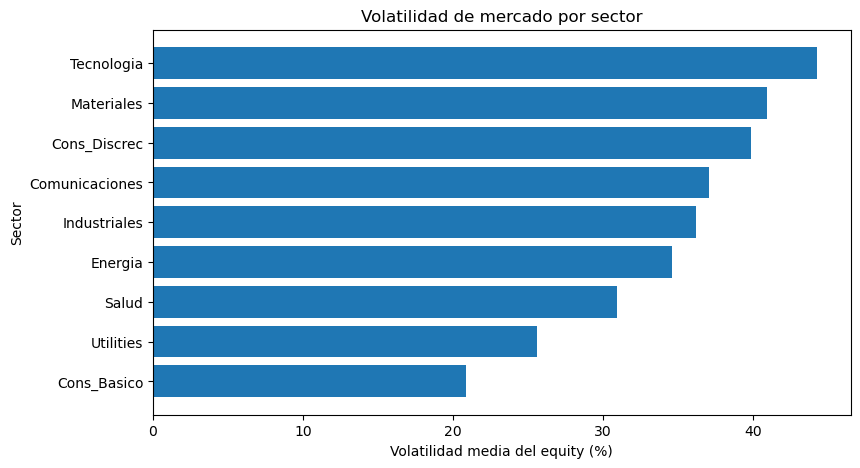

In [15]:
orden=(
    portfolio_model
    .groupby("sector")["sigma_E"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9,5))
plt.barh(orden.index,100*orden.values)
plt.xlabel("Volatilidad media del equity (%)")
plt.ylabel("Sector")
plt.title("Volatilidad de mercado por sector")
plt.show()

## 2.8 Inputs disponibles

Para cada emisor tenemos ahora:

$$
\boxed{
E_i,\quad
\sigma_{E_i},\quad
D_i,\quad
r,\quad
EAD_i,\quad
LGD_i
}
$$

Los cuatro primeros provienen de información de mercado o balance.

Los dos últimos representan la posición de la entidad frente al emisor.

El siguiente problema es que todavía desconocemos:

$$
\boxed{
V_i
\quad\text{y}\quad
\sigma_{V_i}
}
$$

es decir:

- el valor económico de los activos;
- la volatilidad de esos activos.

Estas son precisamente las variables latentes que recuperaremos con el:

$$
\boxed{\text{Modelo de Merton}}
$$

# 3. Modelo de Merton: de datos de mercado a Probability of Default

Para calcular pérdidas de crédito necesitamos una probabilidad de default para cada empresa:

$$
PD_i
$$

El problema es que el default depende del valor económico de los activos de la empresa:

$$
V_i
$$

y de su volatilidad:

$$
\sigma_{V_i}
$$

pero ninguna de estas dos variables se observa directamente.

Sí observamos:

$$
E_i,\quad \sigma_{E_i},\quad D_i,\quad r
$$

donde:

- $E_i$: valor de mercado del equity;
- $\sigma_{E_i}$: volatilidad del equity;
- $D_i$: punto de default;
- $r$: tipo libre de riesgo.

Merton utiliza estas variables observables para inferir:

$$
\boxed{
V_i,\quad \sigma_{V_i}
}
$$

y a partir de ellas calcular:

$$
\boxed{
DD_i \rightarrow PD_i
}
$$

## 3.1 El equity como una opción sobre los activos

Supongamos que toda la deuda vence en $T$.

Al vencimiento pueden ocurrir dos situaciones.

### Si los activos superan la deuda

$$
V_T>D
$$

la empresa paga a los acreedores y los accionistas reciben:

$$
E_T=V_T-D
$$

### Si los activos no cubren la deuda

$$
V_T\leq D
$$

la empresa entra en default y el equity vale:

$$
E_T=0
$$

Por tanto:

$$
\boxed{
E_T=\max(V_T-D,0)
}
$$

que es exactamente el payoff de una opción call:

$$
C_T=\max(S_T-K,0)
$$

con:

$$
S\leftrightarrow V
$$

$$
K\leftrightarrow D
$$

$$
C\leftrightarrow E
$$

Por tanto:

$$
\boxed{
\text{Equity}=\text{Call sobre los activos de la empresa}
}
$$

## 3.2 Primera ecuación: valor del equity

Si el equity es una call sobre los activos, su valor puede escribirse como:

$$
\boxed{
E
=
V\Phi(d_1)
-
De^{-rT}\Phi(d_2)
}
$$

donde:

$$
d_1=
\frac{
\ln(V/D)
+
\left(r+\frac{1}{2}\sigma_V^2\right)T
}{
\sigma_V\sqrt{T}
}
$$

y:

$$
d_2=d_1-\sigma_V\sqrt{T}
$$

Conocemos:

$$
E,\quad D,\quad r,\quad T
$$

pero desconocemos:

$$
V,\quad\sigma_V
$$

Por tanto, necesitamos una segunda ecuación.

## 3.3 Segunda ecuación: volatilidad del equity

Como el equity depende del valor de los activos:

$$
E=f(V)
$$

su sensibilidad frente a cambios en los activos es:

$$
\frac{\partial E}{\partial V}
=
\Phi(d_1)
$$

Aplicando la relación entre volatilidades:

$$
\boxed{
\sigma_E
=
\frac{V}{E}
\Phi(d_1)
\sigma_V
}
$$

Ahora tenemos dos ecuaciones:

$$
E
=
V\Phi(d_1)
-
De^{-rT}\Phi(d_2)
$$

$$
\sigma_E
=
\frac{V}{E}\Phi(d_1)\sigma_V
$$

y dos incógnitas:

$$
\boxed{
V,\quad\sigma_V
}
$$

El problema puede resolverse numéricamente para cada empresa.

In [16]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import root

def estimar_activos_merton(E,sigma_E,D,r,T=1):
    def sistema(x):
        V,sigma_V=x

        d1=(
            np.log(V/D)
            +(r+0.5*sigma_V**2)*T
        )/(sigma_V*np.sqrt(T))

        d2=d1-sigma_V*np.sqrt(T)

        eq1=(
            V*norm.cdf(d1)
            -D*np.exp(-r*T)*norm.cdf(d2)
            -E
        )

        eq2=(
            (V/E)*norm.cdf(d1)*sigma_V
            -sigma_E
        )

        return [eq1,eq2]

    V0=E+D
    sigma_V0=sigma_E*E/(E+D)

    sol=root(
        sistema,
        [V0,sigma_V0]
    )

    if not sol.success:
        return np.nan,np.nan

    V,sigma_V=sol.x
    return V,sigma_V

## 3.4 ¿Qué está resolviendo Python?

Para cada empresa partimos de una primera aproximación:

$$
V^{(0)}\approx E+D
$$

y:

$$
\sigma_V^{(0)}
\approx
\sigma_E
\frac{E}{E+D}
$$

El algoritmo modifica iterativamente:

$$
V
$$

y:

$$
\sigma_V
$$

hasta que ambas ecuaciones de Merton se cumplen simultáneamente.

Por tanto, no observamos directamente el valor de los activos.

Lo estamos **infiriendo a partir del valor y la volatilidad del equity**.

In [17]:
ticker_ejemplo=portfolio_model.index[0]

fila=portfolio_model.loc[ticker_ejemplo]

E=fila["Equity"]
sigma_E=fila["sigma_E"]
D=fila["Debt"]

V,sigma_V=estimar_activos_merton(
    E=E,
    sigma_E=sigma_E,
    D=D,
    r=rf,
    T=1
)

print("Empresa:",ticker_ejemplo)
print(f"Equity:              ${E/1e9:,.2f} bn")
print(f"Default Point:       ${D/1e9:,.2f} bn")
print(f"Volatilidad equity:   {sigma_E:.2%}")
print(f"Valor activos:       ${V/1e9:,.2f} bn")
print(f"Volatilidad activos:  {sigma_V:.2%}")

Empresa: AAL
Equity:              $8.47 bn
Default Point:       $16.87 bn
Volatilidad equity:   48.10%
Valor activos:       $24.61 bn
Volatilidad activos:  16.63%


## 3.5 Distance to Default

Una vez conocemos:

$$
V
\quad\text{y}\quad
\sigma_V
$$

podemos medir qué tan lejos se encuentra la empresa de su barrera de default.

Suponemos que el valor de los activos sigue:

$$
\frac{dV}{V}
=
\mu dt+\sigma_VdW
$$

La Distance to Default es:

$$
\boxed{
DD=
\frac{
\ln(V/D)
+
\left(
\mu-\frac{1}{2}\sigma_V^2
\right)T
}{
\sigma_V\sqrt{T}
}
}
$$

La interpretación es:

> **cuántas desviaciones estándar separan a la empresa de su umbral de default.**

Por tanto:

$$
DD\uparrow
\Rightarrow
\text{empresa más alejada del default}
$$

$$
DD\downarrow
\Rightarrow
\text{empresa más cercana al default}
$$

## 3.6 Probability of Default

Si la Distance to Default está expresada en unidades de una Normal estándar:

$$
\boxed{
PD=\Phi(-DD)
}
$$

Por ejemplo:

$$
DD=1
\Rightarrow
PD\approx15.9\%
$$

$$
DD=2
\Rightarrow
PD\approx2.28\%
$$

$$
DD=3
\Rightarrow
PD\approx0.13\%
$$

$$
DD=4
\Rightarrow
PD\approx0.003\%
$$

La relación es fuertemente no lineal:

$$
\boxed{
DD\uparrow
\Rightarrow
PD\downarrow
}
$$

## 3.7 Tipo libre de riesgo vs rentabilidad esperada de activos

En Merton aparecen dos tasas diferentes.

### $r$

El tipo libre de riesgo aparece en la valoración del equity:

$$
E
=
V\Phi(d_1)
-
De^{-rT}\Phi(d_2)
$$

porque estamos valorando una opción.

---

### $\mu$

La rentabilidad esperada de los activos aparece en:

$$
DD=
\frac{
\ln(V/D)
+
(\mu-\frac12\sigma_V^2)T
}{
\sigma_V\sqrt T
}
$$

porque queremos una probabilidad de default bajo la dinámica económica de los activos.

Por tanto:

$$
\boxed{
r\neq\mu
}
$$

Si utilizáramos:

$$
\mu=r
$$

obtendríamos una probabilidad asociada a una dinámica neutral al riesgo.

En el ejercicio utilizaremos:

$$
\mu=r+\text{prima de riesgo del activo}
$$

In [18]:
ASSET_PREMIUM=0.05

def calcular_pd_merton(V,sigma_V,D,r,T=1,asset_premium=0.05):
    mu=r+asset_premium

    DD=(
        np.log(V/D)
        +(mu-0.5*sigma_V**2)*T
    )/(sigma_V*np.sqrt(T))

    PD=norm.cdf(-DD)

    return DD,PD

In [19]:
DD,PD=calcular_pd_merton(
    V=V,
    sigma_V=sigma_V,
    D=D,
    r=rf,
    T=1,
    asset_premium=ASSET_PREMIUM
)

print("Empresa:",ticker_ejemplo)
print(f"Distance to Default: {DD:.3f}")
print(f"Probability of Default: {PD:.6%}")

Empresa: AAL
Distance to Default: 2.753
Probability of Default: 0.295709%


## 3.8 ¿Qué hace aumentar la PD?

Merton ofrece una interpretación económica muy clara.

### Más deuda

$$
D\uparrow
\Rightarrow
DD\downarrow
\Rightarrow
PD\uparrow
$$

### Menor valor de activos

$$
V\downarrow
\Rightarrow
DD\downarrow
\Rightarrow
PD\uparrow
$$

### Mayor volatilidad

$$
\sigma_V\uparrow
\Rightarrow
DD\downarrow
\Rightarrow
PD\uparrow
$$

Por tanto:

$$
\boxed{
PD=
f(
apalancamiento,
valor\ de\ activos,
volatilidad
)
}
$$

In [20]:
resultados=[]

for ticker,fila in portfolio_model.iterrows():

    E=fila["Equity"]
    sigma_E=fila["sigma_E"]
    D=fila["Debt"]

    V,sigma_V=estimar_activos_merton(
        E=E,
        sigma_E=sigma_E,
        D=D,
        r=rf,
        T=1
    )

    if np.isnan(V):
        continue

    DD,PD=calcular_pd_merton(
        V=V,
        sigma_V=sigma_V,
        D=D,
        r=rf,
        T=1,
        asset_premium=ASSET_PREMIUM
    )

    resultados.append({
        "ticker":ticker,
        "sector":fila["sector"],
        "Equity":E,
        "Debt":D,
        "sigma_E":sigma_E,
        "Asset_Value":V,
        "sigma_V":sigma_V,
        "DD":DD,
        "PD_raw":PD
    })

merton=pd.DataFrame(resultados).set_index("ticker")

merton.head()

,sector,Equity,Debt,sigma_E,Asset_Value,sigma_V,DD,PD_raw
ticker,,,,,,,,
AAL,Industriales,8.473215e+09,1.687450e+10,0.480985,2.461217e+10,0.166323,2.752502,2.957090e-03
ABT,Salud,1.715512e+11,7.981000e+09,0.231122,1.791871e+11,0.221273,14.376295,3.644667e-47
AES,Utilities,1.064744e+10,1.650400e+10,0.373036,2.643762e+10,0.150270,3.687323,1.133127e-04
ALB,Materiales,1.204832e+10,1.633809e+09,0.551628,1.361148e+10,0.488279,4.290562,8.911088e-06
APA,Energia,1.593048e+10,2.353000e+09,0.479002,1.818175e+10,0.419692,4.886578,5.130196e-07


## 3.9 Una limitación práctica: PD extremadamente bajas

Para empresas muy solventes, Merton puede producir:

$$
DD>5
$$

y por tanto:

$$
PD=\Phi(-DD)\approx0
$$

Esto no significa necesariamente que la empresa tenga literalmente riesgo de default cero.

Refleja:

- horizonte corto;
- elevada capitalización;
- baja volatilidad;
- distancia amplia respecto al punto de default;
- supuestos estructurales de Merton.

En aplicaciones reales suelen utilizarse:

- floors regulatorios;
- calibraciones históricas;
- Expected Default Frequencies empíricas.

Para evitar PD numéricamente insignificantes utilizaremos:

$$
\boxed{
PD_{used}
=
\max(PD_{Merton},0.03\%)
}
$$

In [21]:
PD_FLOOR=0.0003

merton["PD"]=np.maximum(
    merton["PD_raw"],
    PD_FLOOR
)

merton[[
    "sector",
    "DD",
    "PD_raw",
    "PD"
]].sort_values("PD",ascending=False).head(15)

,sector,DD,PD_raw,PD
ticker,,,,
LUMN,Comunicaciones,1.445862,7.410790e-02,0.074108
BHC,Salud,1.951799,2.548101e-02,0.025481
XRX,Tecnologia,2.193625,1.413118e-02,0.014131
KSS,Cons_Discrec,2.196209,1.403849e-02,0.014038
CC,Materiales,2.455323,7.037906e-03,0.007038
AAL,Industriales,2.752502,2.957090e-03,0.002957
F,Cons_Discrec,3.381151,3.609147e-04,0.000361
BA,Industriales,5.846901,2.504079e-09,0.000300
NEE,Utilities,7.201559,2.976389e-13,0.000300


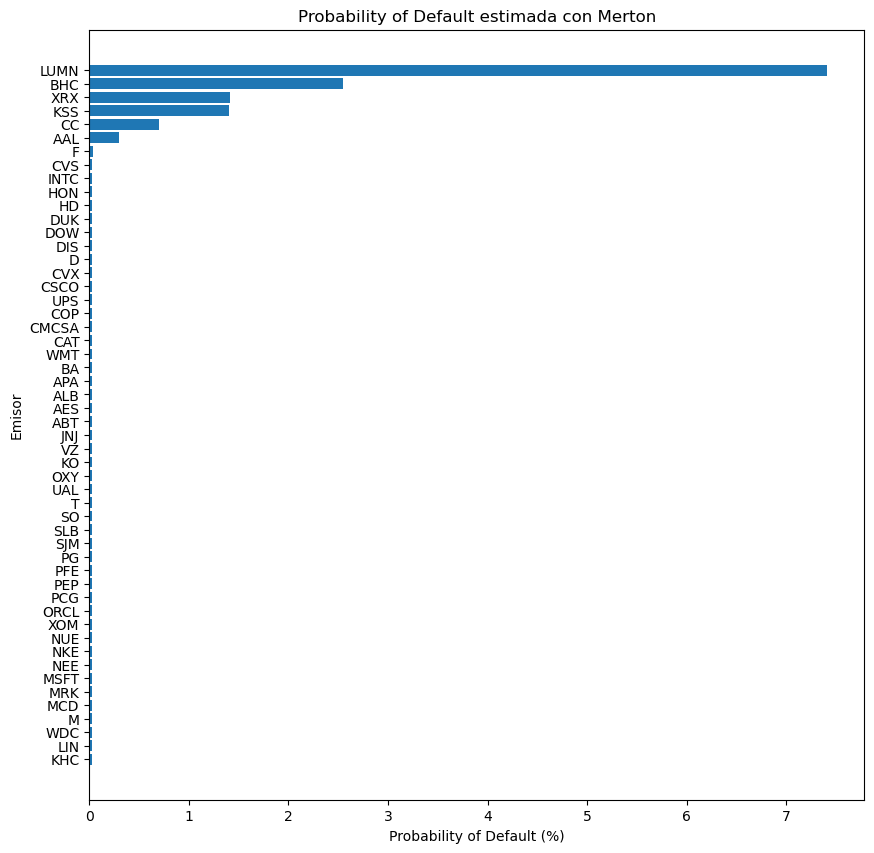

In [22]:
ranking=merton.sort_values("PD")

plt.figure(figsize=(10,10))
plt.barh(
    ranking.index,
    100*ranking["PD"]
)

plt.xlabel("Probability of Default (%)")
plt.ylabel("Emisor")
plt.title("Probability of Default estimada con Merton")
plt.show()

In [23]:
pd_sector=(
    merton
    .groupby("sector")
    .agg(
        empresas=("PD","size"),
        PD_media=("PD","mean"),
        DD_medio=("DD","mean"),
        sigma_V_media=("sigma_V","mean")
    )
    .sort_values("PD_media",ascending=False)
)

pd_sector

,empresas,PD_media,DD_medio,sigma_V_media
sector,,,,
Comunicaciones,5,0.015062,6.121917,0.221828
Salud,6,0.004497,10.361904,0.198685
Tecnologia,6,0.002605,8.750381,0.341718
Cons_Discrec,6,0.002600,6.867600,0.284534
Materiales,5,0.001648,6.814373,0.314482
Industriales,6,0.000743,6.267402,0.256611
Cons_Basico,6,0.000300,13.203640,0.179236
Energia,6,0.000300,8.928273,0.314595
Utilities,6,0.000300,7.084742,0.151253


## 3.10 ¿Merton nos da ya el Capital Económico?

No.

Merton nos ha permitido estimar:

$$
\boxed{
PD_i
}
$$

para cada empresa.

Pero el Capital Económico es una propiedad de la **cartera**.

Todavía desconocemos:

$$
P(Default_i,Default_j)
$$

y, más generalmente:

$$
P(
\text{deterioro simultáneo de múltiples emisores}
)
$$

Dos carteras con las mismas PD individuales pueden tener Capital Económico muy diferente si cambia la dependencia entre empresas.

Por tanto, el siguiente paso será explicar esa dependencia a partir de variables macroeconómicas comunes.

# Siguiente paso

Ya tenemos:

$$
\boxed{
PD_1,\ldots,PD_N
}
$$

Ahora necesitamos entender por qué estas probabilidades pueden deteriorarse conjuntamente.

Las empresas están expuestas a variables como:

- crecimiento económico;
- desempleo;
- inflación;
- tipos de interés;
- spreads;
- condiciones financieras.

El problema es que estas variables están fuertemente correlacionadas.

Por ello utilizaremos:

$$
\boxed{\text{PCA sobre variables macroeconómicas}}
$$

para transformar muchos indicadores correlacionados en unos pocos factores económicos ortogonales.

# 4. Factores macroeconómicos y PCA

La calidad crediticia de las empresas no evoluciona de forma independiente.

Variables como:

- actividad económica;
- desempleo;
- inflación;
- tipos de interés;
- spreads de crédito;

afectan simultáneamente a muchas empresas.

El problema es que estas variables también están correlacionadas entre sí.

Por ejemplo, durante una recesión podemos observar simultáneamente:

$$
Actividad\downarrow,\qquad
Desempleo\uparrow,\qquad
Spreads\uparrow
$$

Si introducimos todas estas variables directamente en un modelo:

$$
\Delta DD_t
=
\beta_1 X_{1,t}
+\beta_2 X_{2,t}
+\cdots+
\beta_K X_{K,t}
+\varepsilon_t
$$

podemos generar **multicolinealidad** y estar utilizando varias variables para representar el mismo shock económico.

Por ello utilizaremos PCA para transformar las variables macro originales en factores no correlacionados:

$$
\boxed{
X_1,\ldots,X_K
\rightarrow
PC_1,\ldots,PC_K
}
$$

con:

$$
Corr(PC_j,PC_k)=0
\qquad j\neq k
$$

Estos componentes serán nuestros **factores macroeconómicos sistemáticos**.

## 4.1 Variables macroeconómicas

Utilizaremos seis dimensiones del entorno económico estadounidense:

| Variable | Serie FRED | Interpretación |
|---|---|---|
| Producción industrial | `INDPRO` | Actividad económica |
| Desempleo | `UNRATE` | Mercado laboral |
| CPI | `CPIAUCSL` | Inflación |
| Treasury 1Y | `DGS1` | Tipo de interés de corto plazo |
| Baa spread | `BAA10Y` | Riesgo / condiciones crediticias |
| Pendiente 10Y–2Y | `T10Y2Y` | Ciclo monetario / expectativas |

No utilizaremos directamente los niveles de todas las series.

Transformaremos las variables cuando sea necesario para obtener magnitudes económicamente comparables:

$$
IndustrialProduction
\rightarrow
\Delta_{12m}\log(INDPRO)
$$

$$
CPI
\rightarrow
\Delta_{12m}\log(CPI)
$$

El resto se mantendrá en nivel.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def fred_series(serie):
    url=f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}"
    x=pd.read_csv(url)
    x.iloc[:,0]=pd.to_datetime(x.iloc[:,0])
    x=x.set_index(x.columns[0])
    return pd.to_numeric(x.iloc[:,0],errors="coerce").rename(serie)

indpro=fred_series("INDPRO").resample("ME").last()
unrate=fred_series("UNRATE").resample("ME").last()
cpi=fred_series("CPIAUCSL").resample("ME").last()
dgs1=fred_series("DGS1").resample("ME").mean()
baa=fred_series("BAA10Y").resample("ME").mean()
slope=fred_series("T10Y2Y").resample("ME").mean()

macro=pd.concat([indpro,unrate,cpi,dgs1,baa,slope],axis=1)
macro.tail()

c:\Users\lagavidia.UPCONT\AppData\Local\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)
c:\Users\lagavidia.UPCONT\AppData\Local\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)
c:\Users\lagavidia.UPCONT\AppData\Local\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Cal

,INDPRO,UNRATE,CPIAUCSL,DGS1,BAA10Y,T10Y2Y
observation_date,,,,,,
2026-06-30,102.8420,4.2,332.568,3.909524,1.530476,0.357619
2026-07-31,103.0454,4.1,332.813,4.050909,1.585909,0.376818
2026-08-31,103.0682,4.1,334.131,4.031429,1.631905,0.468095
2026-09-30,NaN,4.2,NaN,4.365238,1.481429,0.337619
2026-10-31,NaN,NaN,NaN,4.450000,1.470000,0.474000


## 4.2 Transformación de las variables

No debemos aplicar PCA directamente a series con tendencias muy diferentes.

Construiremos:

### Crecimiento de producción industrial

$$
g_{INDPRO,t}
=
100\left[
\ln(INDPRO_t)-\ln(INDPRO_{t-12})
\right]
$$

### Inflación

$$
\pi_t
=
100\left[
\ln(CPI_t)-\ln(CPI_{t-12})
\right]
$$

Mantendremos en nivel:

$$
UNRATE,\quad DGS1,\quad BAA10Y,\quad T10Y2Y
$$

El resultado será un vector macroeconómico mensual:

$$
X_t=
\begin{bmatrix}
Actividad_t\\
Desempleo_t\\
Inflación_t\\
Tipos_t\\
Spread_t\\
Pendiente_t
\end{bmatrix}
$$

In [25]:
macro_model=pd.DataFrame(index=macro.index)

macro_model["Actividad"]=100*(np.log(macro["INDPRO"])-np.log(macro["INDPRO"].shift(12)))
macro_model["Desempleo"]=macro["UNRATE"]
macro_model["Inflacion"]=100*(np.log(macro["CPIAUCSL"])-np.log(macro["CPIAUCSL"].shift(12)))
macro_model["Tipos_1Y"]=macro["DGS1"]
macro_model["Baa_Spread"]=macro["BAA10Y"]
macro_model["Pendiente_10Y2Y"]=macro["T10Y2Y"]

macro_model=macro_model.loc["2005":].dropna()

macro_model.tail()

,Actividad,Desempleo,Inflacion,Tipos_1Y,Baa_Spread,Pendiente_10Y2Y
observation_date,,,,,,
2026-04-30,1.424036,4.3,3.709582,3.693636,1.711429,0.520000
2026-05-31,1.644495,4.3,4.082150,3.792000,1.619000,0.489000
2026-06-30,1.334688,4.2,3.404900,3.909524,1.530476,0.357619
2026-07-31,1.123661,4.1,3.250452,4.050909,1.585909,0.376818
2026-08-31,1.410429,4.1,3.298029,4.031429,1.631905,0.468095


## 4.3 El problema: las variables macro están correlacionadas

Si utilizamos simultáneamente todas las variables originales, parte de la información se repite.

La matriz:

$$
R=Corr(X)
$$

nos permite identificar esa dependencia.

Una elevada correlación entre variables implica que introducirlas conjuntamente en una regresión puede dificultar la identificación del efecto individual de cada una.

PCA resolverá este problema construyendo factores ortogonales.

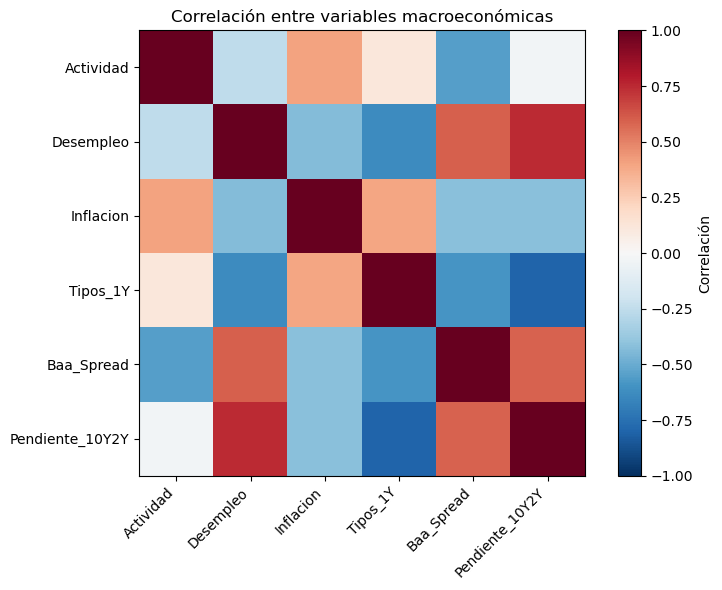

,Actividad,Desempleo,Inflacion,Tipos_1Y,Baa_Spread,Pendiente_10Y2Y
Actividad,1.00,-0.26,0.41,0.12,-0.55,-0.03
Desempleo,-0.26,1.00,-0.43,-0.63,0.60,0.74
Inflacion,0.41,-0.43,1.00,0.40,-0.41,-0.41
Tipos_1Y,0.12,-0.63,0.40,1.00,-0.59,-0.80
Baa_Spread,-0.55,0.60,-0.41,-0.59,1.00,0.59
Pendiente_10Y2Y,-0.03,0.74,-0.41,-0.80,0.59,1.00


In [26]:
corr_macro=macro_model.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr_macro,cmap="RdBu_r",vmin=-1,vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr_macro)),corr_macro.columns,rotation=45,ha="right")
plt.yticks(range(len(corr_macro)),corr_macro.columns)
plt.title("Correlación entre variables macroeconómicas")
plt.tight_layout()
plt.show()

corr_macro.round(2)

## 4.4 Estandarización

Las variables tienen escalas completamente diferentes.

Por ejemplo:

- desempleo: porcentaje;
- tipos: porcentaje;
- spread: puntos porcentuales;
- crecimiento industrial: tasa de crecimiento.

Si aplicáramos PCA directamente, las variables con mayor varianza numérica dominarían el resultado.

Por ello estandarizamos:

$$
\boxed{
Z_{j,t}
=
\frac{
X_{j,t}-\bar X_j
}{
\sigma_j
}
}
$$

Después de la transformación:

$$
E[Z_j]=0
$$

y:

$$
Var(Z_j)=1
$$

El PCA se realizará sobre estas variables estandarizadas.

In [27]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

Z=scaler.fit_transform(macro_model)

macro_z=pd.DataFrame(
    Z,
    index=macro_model.index,
    columns=macro_model.columns
)

macro_z.describe().round(2)

,Actividad,Desempleo,Inflacion,Tipos_1Y,Baa_Spread,Pendiente_10Y2Y
count,259.00,259.00,259.00,259.00,259.00,259.00
mean,-0.00,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-4.20,-1.10,-2.52,-1.02,-1.27,-2.01
25%,-0.29,-0.76,-0.57,-0.93,-0.74,-0.80
50%,0.25,-0.38,-0.14,-0.38,-0.23,-0.15
75%,0.52,0.64,0.41,1.03,0.54,0.76
max,3.23,4.34,3.35,1.88,4.62,2.00


## 4.5 Principal Component Analysis

PCA busca combinaciones lineales:

$$
PC_{k,t}
=
w_{1k}Z_{1,t}
+
w_{2k}Z_{2,t}
+\cdots+
w_{Kk}Z_{K,t}
$$

tales que:

$$
Var(PC_1)
>
Var(PC_2)
>
\cdots
$$

y además:

$$
\boxed{
Corr(PC_j,PC_k)=0
}
$$

Cada componente representa un shock macroeconómico distinto.

La descomposición puede expresarse como:

$$
\boxed{
Z=W F
}
$$

donde:

- $Z$: variables macro estandarizadas;
- $F$: factores PCA;
- $W$: loadings.

Nuestro objetivo no es conservar todos los componentes.

Queremos encontrar el menor número de factores capaz de explicar una proporción elevada de la variación macroeconómica.

In [28]:
from sklearn.decomposition import PCA

pca=PCA()
scores=pca.fit_transform(macro_z)

var_exp=pca.explained_variance_ratio_
var_acum=np.cumsum(var_exp)

resultado_pca=pd.DataFrame({
    "Componente":[f"PC{i+1}" for i in range(len(var_exp))],
    "Varianza_exp":var_exp,
    "Varianza_acum":var_acum
})

resultado_pca

,Componente,Varianza_exp,Varianza_acum
0,PC1,0.569662,0.569662
1,PC2,0.201061,0.770723
2,PC3,0.104549,0.875272
3,PC4,0.062387,0.937659
4,PC5,0.039069,0.976729
5,PC6,0.023271,1.000000


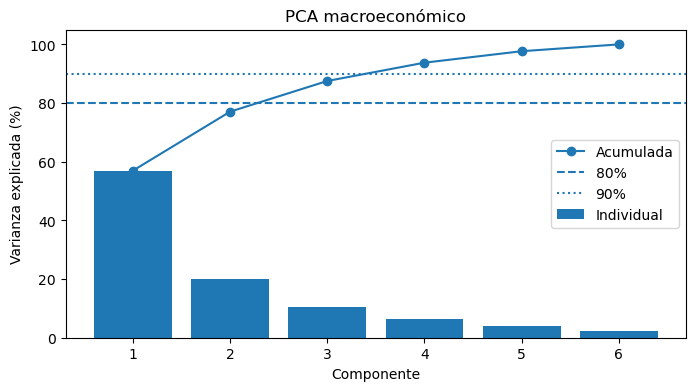

In [29]:
plt.figure(figsize=(8,4))

x=np.arange(1,len(var_exp)+1)

plt.bar(x,100*var_exp,label="Individual")
plt.plot(x,100*var_acum,marker="o",label="Acumulada")
plt.axhline(80,ls="--",label="80%")
plt.axhline(90,ls=":",label="90%")

plt.xlabel("Componente")
plt.ylabel("Varianza explicada (%)")
plt.title("PCA macroeconómico")
plt.xticks(x)
plt.legend()
plt.show()

In [30]:
TARGET_VAR=0.80

n_factores=np.argmax(var_acum>=TARGET_VAR)+1

print(f"Número de factores retenidos: {n_factores}")
print(f"Varianza explicada: {var_acum[n_factores-1]:.2%}")

Número de factores retenidos: 3
Varianza explicada: 87.53%


### ¿Cuántos factores conservar?

Utilizaremos el menor número $K$ que cumpla:

$$
\boxed{
\sum_{k=1}^{K}
VarExp(PC_k)
\geq80\%
}
$$

No imponemos previamente que existan dos, tres o cuatro factores.

La estructura debe surgir de los datos.

## 4.6 Interpretación económica: loadings

Los componentes principales por sí solos no tienen un nombre económico.

Para interpretarlos observamos sus **loadings**:

$$
w_{jk}
$$

que indican cuánto contribuye cada variable original al componente $k$.

Por ejemplo, si encontramos un componente con:

$$
Actividad<0
$$

$$
Desempleo>0
$$

$$
BaaSpread>0
$$

podríamos interpretarlo como un:

$$
\boxed{\text{factor de deterioro cíclico / estrés}}
$$

Otro componente podría cargar especialmente sobre:

$$
Inflación,\quad Tipos
$$

y representar condiciones monetarias.

Los nombres de los factores deben surgir de los loadings, no imponerse antes de estimar el PCA.

In [31]:
loadings=pd.DataFrame(
    pca.components_[:n_factores].T,
    index=macro_model.columns,
    columns=[f"PC{i+1}" for i in range(n_factores)]
)

loadings.round(3)

,PC1,PC2,PC3
Actividad,-0.236,0.771,-0.227
Desempleo,0.456,0.142,0.070
Inflacion,-0.350,0.289,0.865
Tipos_1Y,-0.448,-0.311,-0.057
Baa_Spread,0.448,-0.226,0.437
Pendiente_10Y2Y,0.460,0.392,-0.010


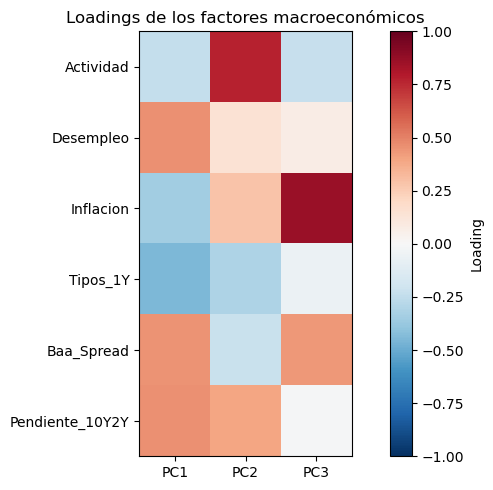

In [32]:
plt.figure(figsize=(8,5))

plt.imshow(loadings,cmap="RdBu_r",vmin=-1,vmax=1)
plt.colorbar(label="Loading")

plt.xticks(
    range(n_factores),
    loadings.columns
)

plt.yticks(
    range(len(loadings)),
    loadings.index
)

plt.title("Loadings de los factores macroeconómicos")
plt.tight_layout()
plt.show()

### El signo de un componente principal es arbitrario

Si:

$$
PC_1
$$

es una solución del PCA, entonces:

$$
-PC_1
$$

también lo es.

Por tanto, que un loading aparezca positivo o negativo no tiene significado por sí solo.

Lo importante es la **relación entre los signos**.

Por ejemplo:

$$
Actividad:-0.6
$$

$$
Desempleo:+0.7
$$

describe el mismo factor económico que:

$$
Actividad:+0.6
$$

$$
Desempleo:-0.7
$$

simplemente con orientación contraria.

Para facilitar la interpretación podemos orientar posteriormente los factores.

In [33]:
macro_factors=pd.DataFrame(
    scores[:,:n_factores],
    index=macro_model.index,
    columns=[f"PC{i+1}" for i in range(n_factores)]
)

macro_factors.tail()

,PC1,PC2,PC3
observation_date,,,
2026-04-30,-1.615518,-0.015274,0.016351
2026-05-31,-1.791089,0.078566,0.130034
2026-06-30,-1.808977,-0.137480,-0.235035
2026-07-31,-1.782768,-0.235917,-0.275736
2026-08-31,-1.730806,-0.152352,-0.241635


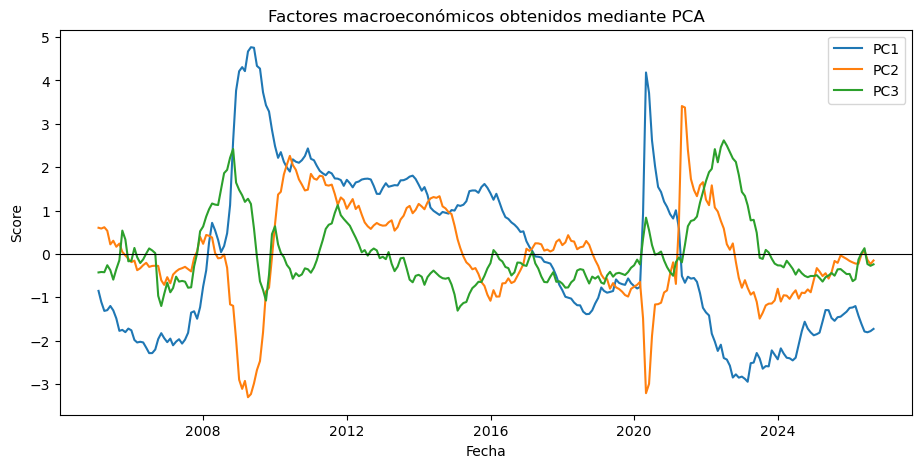

In [34]:
plt.figure(figsize=(11,5))

for col in macro_factors.columns:
    plt.plot(
        macro_factors.index,
        macro_factors[col],
        label=col
    )

plt.axhline(0,color="black",lw=.8)
plt.xlabel("Fecha")
plt.ylabel("Score")
plt.title("Factores macroeconómicos obtenidos mediante PCA")
plt.legend()
plt.show()

In [35]:
macro_factors.corr().round(3)

,PC1,PC2,PC3
PC1,1.0,0.0,0.0
PC2,0.0,1.0,-0.0
PC3,0.0,-0.0,1.0


## 4.7 ¿Qué hemos conseguido?

Antes teníamos:

$$
X_1,\ldots,X_6
$$

con correlaciones importantes entre ellas.

Ahora tenemos:

$$
PC_1,\ldots,PC_K
$$

tales que:

$$
\boxed{
Corr(PC_j,PC_k)\approx0
}
$$

Hemos transformado varias variables macroeconómicas correlacionadas en unos pocos shocks independientes.

Esto reduce:

- multicolinealidad;
- redundancia;
- dimensionalidad.

Pero mantenemos la mayor parte de la información macroeconómica original.

In [36]:
def mean_abs_offdiag(C):
    C=np.asarray(C)
    return (
        np.abs(C).sum()-np.abs(np.diag(C)).sum()
    )/(C.size-len(C))

corr_original=mean_abs_offdiag(macro_z.corr())
corr_factores=mean_abs_offdiag(macro_factors.corr())

print(f"Correlación absoluta media — variables macro: {corr_original:.3f}")
print(f"Correlación absoluta media — factores PCA:   {corr_factores:.3f}")

Correlación absoluta media — variables macro: 0.464
Correlación absoluta media — factores PCA:   0.000


# 4.8 De factores macro a calidad crediticia

Los factores PCA no son el resultado final.

Nuestro objetivo es utilizarlos para explicar el deterioro de la calidad crediticia.

Para cada empresa $i$ plantearemos:

$$
\boxed{
\Delta DD_{i,t}
=
\alpha_i
+
\beta_{i1}PC_{1,t}
+\cdots+
\beta_{iK}PC_{K,t}
+
\varepsilon_{i,t}
}
$$

donde:

$$
\beta_{ik}
$$

mide la sensibilidad crediticia de la empresa $i$ al shock macroeconómico $k$.

Por tanto:

$$
\boxed{
Macro
\rightarrow
PCA
\rightarrow
Factores
\rightarrow
Distance\ to\ Default
}
$$

### Sensibilidad diferente entre empresas

Las empresas no tienen por qué responder igual al mismo shock.

Por ejemplo:

$$
\beta_{Industriales,1}
\neq
\beta_{Salud,1}
$$

Una empresa industrial puede presentar una fuerte sensibilidad al ciclo:

$$
|\beta_{i,PC1}|\uparrow
$$

mientras que una empresa defensiva puede tener:

$$
|\beta_{i,PC1}|\downarrow
$$

Por tanto, los factores macro serán comunes:

$$
PC_{1,t},\ldots,PC_{K,t}
$$

pero las exposiciones a esos factores serán específicas de cada empresa:

$$
\boxed{
\beta_{i1},\ldots,\beta_{iK}
}
$$

Este mecanismo generará posteriormente dependencia entre los deterioros crediticios.

## 4.9 Modelo sistemático de crédito

Podemos resumir el movimiento de la calidad crediticia como:

$$
\boxed{
Z_{i,t}
=
\beta_i'F_t
+
\sigma_{\varepsilon_i}\varepsilon_{i,t}
}
$$

donde:

$$
F_t=
\begin{bmatrix}
PC_{1,t}\\
\vdots\\
PC_{K,t}
\end{bmatrix}
$$

representa los factores macroeconómicos comunes y:

$$
\varepsilon_{i,t}
$$

representa el shock específico de la empresa.

Por tanto:

$$
\boxed{
\text{Riesgo de empresa}
=
\text{riesgo sistemático}
+
\text{riesgo idiosincrático}
}
$$

Dos empresas pueden deteriorarse simultáneamente porque comparten exposición a:

$$
F_t
$$

aunque sus shocks idiosincráticos sean independientes.

# Siguiente paso

Tenemos ahora dos piezas del modelo:

### Riesgo individual

Merton nos ha proporcionado:

$$
\boxed{
PD_i,\quad DD_i
}
$$

### Riesgo sistemático

PCA nos ha proporcionado:

$$
\boxed{
PC_1,\ldots,PC_K
}
$$

El siguiente paso es estimar:

$$
\boxed{
\beta_{ik}
}
$$

es decir:

> **cómo responde la calidad crediticia de cada empresa a cada factor macroeconómico.**

Para ello necesitaremos construir una serie temporal de calidad crediticia para cada emisor y estimar el modelo:

$$
\Delta DD_{i,t}
=
\alpha_i+\beta_i'F_t+\varepsilon_{i,t}
$$

# 5. De los factores macroeconómicos al riesgo de crédito

Ya tenemos:

### Riesgo crediticio individual

Merton nos proporciona para cada empresa:

$$
DD_i,\qquad PD_i
$$

### Factores macroeconómicos

PCA ha transformado las variables macro correlacionadas en:

$$
PC_{1,t},\ldots,PC_{K,t}
$$

con:

$$
Corr(PC_j,PC_k)=0
$$

Ahora queremos responder:

> **¿Cómo cambia la calidad crediticia de cada empresa cuando cambian los factores macroeconómicos?**

Estimaremos:

$$
\boxed{
\Delta DD_{i,t}
=
\alpha_i+
\beta_{i1}PC_{1,t}
+\cdots+
\beta_{iK}PC_{K,t}
+\varepsilon_{i,t}
}
$$

donde:

- $\beta_{ik}$ = sensibilidad del emisor $i$ al factor macro $k$;
- $\varepsilon_{i,t}$ = componente idiosincrático no explicado por la macroeconomía.

Por tanto:

$$
\boxed{
\text{movimiento crediticio}
=
\text{componente sistemático}
+
\text{componente idiosincrático}
}
$$

## 5.1 ¿Por qué utilizar $\Delta DD$?

La Distance to Default en nivel puede presentar persistencia:

$$
DD_{i,t}\approx DD_{i,t-1}
$$

Nos interesa explicar el **deterioro o mejora crediticia durante cada periodo**.

Por ello trabajaremos con:

$$
\boxed{
\Delta DD_{i,t}
=
DD_{i,t}-DD_{i,t-1}
}
$$

Interpretación:

$$
\Delta DD>0
\Rightarrow
\text{mejora crediticia}
$$

$$
\Delta DD<0
\Rightarrow
\text{deterioro crediticio}
$$

Como:

$$
PD=\Phi(-DD)
$$

una caída de DD implica:

$$
DD\downarrow
\Rightarrow
PD\uparrow
$$

In [37]:
# Capitalización bursátil histórica aproximada:
# precio histórico × acciones actuales en circulación

dd_hist={}

for ticker in portfolio_model.index:
    if ticker not in prices.columns:
        continue

    shares=portfolio_model.loc[ticker,"shares"]
    D=portfolio_model.loc[ticker,"Debt"]

    if not np.isfinite(shares) or not np.isfinite(D) or D<=0:
        continue

    p=prices[ticker].dropna()
    E=p*shares

    # Volatilidad móvil del equity: 252 días
    ret=np.log(p/p.shift(1))
    sigma_E_roll=ret.rolling(252,min_periods=126).std()*np.sqrt(252)

    DD_series=[]

    for fecha in p.index:
        sigma_E_t=sigma_E_roll.loc[fecha]

        if not np.isfinite(sigma_E_t):
            DD_series.append(np.nan)
            continue

        E_t=E.loc[fecha]

        try:
            V_t,sigma_V_t=estimar_activos_merton(
                E=E_t,
                sigma_E=sigma_E_t,
                D=D,
                r=rf,
                T=1
            )

            if not np.isfinite(V_t) or not np.isfinite(sigma_V_t):
                DD_series.append(np.nan)
                continue

            DD_t,_=calcular_pd_merton(
                V=V_t,
                sigma_V=sigma_V_t,
                D=D,
                r=rf,
                T=1,
                asset_premium=ASSET_PREMIUM
            )

            DD_series.append(DD_t)

        except:
            DD_series.append(np.nan)

    dd_hist[ticker]=pd.Series(
        DD_series,
        index=p.index
    )

dd_daily=pd.DataFrame(dd_hist)
dd_daily.tail()

,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-02,2.795980,12.255628,4.796774,4.155984,5.052343,6.360961,2.433716,7.343694,2.137674,4.848887,...,7.492033,10.537179,7.026186,3.674100,7.524157,6.949707,5.099827,13.658168,13.792207,1.178344
2026-10-05,2.795144,12.274867,4.961885,4.162496,5.091694,6.355836,2.429171,7.358037,2.144469,4.855473,...,7.558466,10.554820,7.042912,3.650176,7.534603,6.952767,5.156874,13.679096,13.798259,1.179398
2026-10-06,2.797515,12.198503,4.975659,4.183560,5.108159,6.322621,2.423538,7.392160,2.149574,4.862177,...,7.545264,10.548113,7.053779,3.664297,7.541656,6.959330,5.046288,13.708150,13.834758,1.182053
2026-10-07,2.797425,12.214979,4.991351,4.144881,5.103078,6.314133,2.421326,7.183306,2.148008,4.845076,...,7.404251,10.567023,7.173509,3.650018,7.518889,7.112964,5.040849,13.734034,13.828692,1.177764
2026-10-08,2.798113,12.208717,4.993864,4.138843,5.142864,6.311338,2.424557,7.135373,2.150349,4.859230,...,7.438457,10.594925,7.195590,3.620633,7.548856,7.127509,5.010633,13.763272,13.853527,1.180630


### Aproximación utilizada

Idealmente, un Merton histórico completo debería actualizar en cada fecha:

$$
E_t,\quad \sigma_{E,t},\quad D_t,\quad r_t
$$

En nuestro ejercicio actualizamos:

$$
E_t,\quad\sigma_{E,t}
$$

con datos diarios de mercado, mientras mantenemos el punto de default:

$$
D
$$

constante en su valor observado más reciente.

Por tanto, esta serie debe interpretarse como una:

$$
\boxed{\text{DD de mercado aproximada}}
$$

y no como una reconstrucción histórica completa de KMV.

Para una clase práctica tiene una ventaja: nos permite aislar cómo las condiciones de mercado modifican la calidad crediticia manteniendo fija la estructura de deuda.

In [38]:
# Última DD observable de cada mes
dd_monthly=dd_daily.resample("ME").last()

# Cambios mensuales
delta_dd=dd_monthly.diff()

print("Periodo DD:")
print(delta_dd.index.min(), "→", delta_dd.index.max())
print("Empresas:",delta_dd.shape[1])

delta_dd.tail()

Periodo DD:
2021-10-31 00:00:00 → 2026-10-31 00:00:00
Empresas: 52


,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
Date,,,,,,,,,,,,,,,,,,,,,
2026-06-30,0.017147,-0.296227,0.149720,-0.429537,-0.102195,-0.203713,-0.015950,-0.365492,-0.048944,-0.267347,...,-0.591905,-0.400819,-1.125183,0.115466,-0.277188,-0.912930,-0.585754,-0.364388,-0.389588,-0.021092
2026-07-31,-0.026320,-0.189485,0.619568,0.108791,0.177002,-0.199441,-0.501017,-1.124032,-0.077611,-0.282210,...,0.021155,-0.514109,-0.127778,0.000903,0.322217,-0.019962,-0.832318,-0.623075,0.213064,-0.100286
2026-08-31,0.056937,0.041529,0.140084,0.224173,0.156147,-0.247614,0.132649,-0.163419,-0.046505,0.069928,...,0.240357,-0.269295,0.111138,-0.075615,-0.042973,0.062958,-0.464017,-0.951688,-0.237332,0.087974
2026-09-30,-0.009497,-0.410350,0.108045,-0.230102,0.002021,-0.372617,0.017986,0.010295,-0.039193,-0.442566,...,-0.633073,-0.276789,-0.218491,-0.032565,-0.477558,-0.308819,0.018185,-0.219634,-0.099198,-0.002525
2026-10-31,-0.006896,-0.130076,0.782487,0.014463,0.154490,-0.009618,-0.006554,-0.138224,0.016326,0.000794,...,-0.026500,0.089829,0.196654,-0.024950,0.020105,0.193521,-0.223981,0.126762,0.114255,0.007313


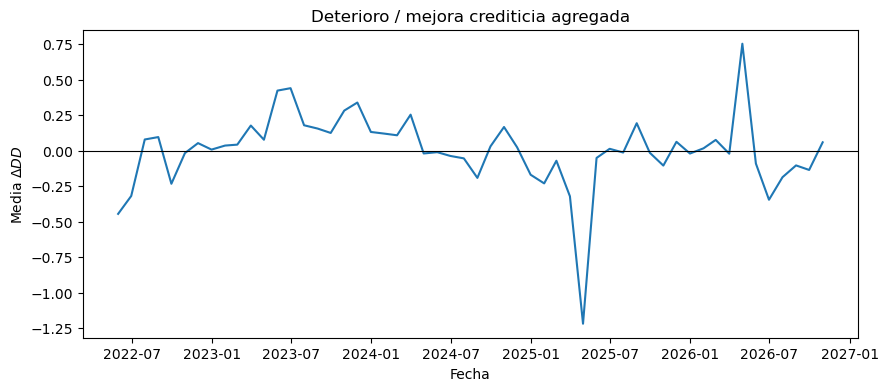

In [39]:
# Media cross-section: movimiento agregado de DD
credit_cycle=delta_dd.mean(axis=1)

plt.figure(figsize=(10,4))
plt.plot(credit_cycle.index,credit_cycle)
plt.axhline(0,color="black",lw=.8)
plt.ylabel(r"Media $\Delta DD$")
plt.xlabel("Fecha")
plt.title("Deterioro / mejora crediticia agregada")
plt.show()

In [40]:
# Fechas comunes entre factores PCA y DD
datos_modelo=pd.concat(
    [
        delta_dd.add_prefix("DD_"),
        macro_factors
    ],
    axis=1
).dropna(how="all")

factores=macro_factors.columns.tolist()

print("Factores utilizados:",factores)
print("Periodo común:",
      max(delta_dd.index.min(),macro_factors.index.min()),
      "→",
      min(delta_dd.index.max(),macro_factors.index.max()))

Factores utilizados: ['PC1', 'PC2', 'PC3']
Periodo común: 2021-10-31 00:00:00 → 2026-08-31 00:00:00


## 5.2 Estimación de las sensibilidades macro

Para cada empresa estimamos:

$$
\Delta DD_{i,t}
=
\alpha_i+
\sum_{k=1}^{K}
\beta_{ik}PC_{k,t}
+
\varepsilon_{i,t}
$$

Como los componentes PCA son ortogonales:

$$
Corr(PC_j,PC_k)=0
$$

reducimos el problema de multicolinealidad que tendríamos utilizando directamente:

$$
PIB,\ Desempleo,\ Inflación,\ Tipos,\ Spreads,\ldots
$$

Los coeficientes:

$$
\boxed{\beta_{ik}}
$$

miden la exposición crediticia de cada empresa a cada shock macro.

In [41]:
resultados_beta=[]
residuos={}

for ticker in delta_dd.columns:

    df=pd.concat(
        [
            delta_dd[ticker].rename("dDD"),
            macro_factors
        ],
        axis=1
    ).dropna()

    if len(df)<24:
        continue

    y=df["dDD"].values
    X=df[factores].values

    # Añadimos constante
    X_reg=np.column_stack([np.ones(len(X)),X])

    coef=np.linalg.lstsq(
        X_reg,
        y,
        rcond=None
    )[0]

    pred=X_reg@coef
    resid=y-pred

    ss_res=np.sum(resid**2)
    ss_tot=np.sum((y-y.mean())**2)
    r2=1-ss_res/ss_tot if ss_tot>0 else np.nan

    fila={
        "ticker":ticker,
        "sector":portfolio_model.loc[ticker,"sector"],
        "alpha":coef[0],
        "R2":r2,
        "n_obs":len(df)
    }

    for k,factor in enumerate(factores):
        fila[f"beta_{factor}"]=coef[k+1]

    resultados_beta.append(fila)

    residuos[ticker]=pd.Series(
        resid,
        index=df.index
    )

betas=pd.DataFrame(resultados_beta).set_index("ticker")

betas.head()

,sector,alpha,R2,n_obs,beta_PC1,beta_PC2,beta_PC3
ticker,,,,,,,
AAL,Industriales,-0.147307,0.094527,51,-0.063528,-0.044139,-0.001098
ABT,Salud,-0.324142,0.274009,51,0.025563,-0.628739,0.131118
AES,Utilities,-0.101323,0.041540,51,-0.066298,0.066775,-0.065863
ALB,Materiales,0.111561,0.023144,51,0.061221,0.026042,0.039280
APA,Energia,-0.775301,0.118404,51,-0.449773,0.183357,-0.210401


## 5.3 Interpretación de las betas

Supongamos que:

$$
\beta_{i,1}=0.30
$$

Entonces un aumento de una unidad en:

$$
PC_1
$$

produce, en promedio:

$$
0.30
$$

unidades adicionales de Distance to Default.

Si hemos interpretado PC1 como un factor de expansión:

$$
PC_1\uparrow
\Rightarrow
DD_i\uparrow
\Rightarrow
PD_i\downarrow
$$

Una beta positiva significa que la empresa se beneficia de ese shock.

Por el contrario:

$$
\beta_{i,1}<0
$$

significaría que el mismo shock deteriora su calidad crediticia.

El signo debe interpretarse siempre conjuntamente con los **loadings del PCA**.

In [42]:
beta_cols=[
    c for c in betas.columns
    if c.startswith("beta_")
]

betas_sector=(
    betas
    .groupby("sector")[beta_cols+["R2"]]
    .mean()
)

betas_sector.round(3)

,beta_PC1,beta_PC2,beta_PC3,R2
sector,,,,
Comunicaciones,-0.084,0.007,-0.070,0.071
Cons_Basico,0.418,-0.932,0.318,0.188
Cons_Discrec,0.166,-0.331,0.121,0.094
Energia,-0.522,0.052,-0.210,0.124
Industriales,-0.071,-0.097,0.010,0.059
Materiales,-0.224,-0.027,-0.069,0.062
Salud,0.101,-0.218,0.111,0.148
Tecnologia,-0.033,-0.327,0.061,0.131
Utilities,0.226,-0.248,0.072,0.123


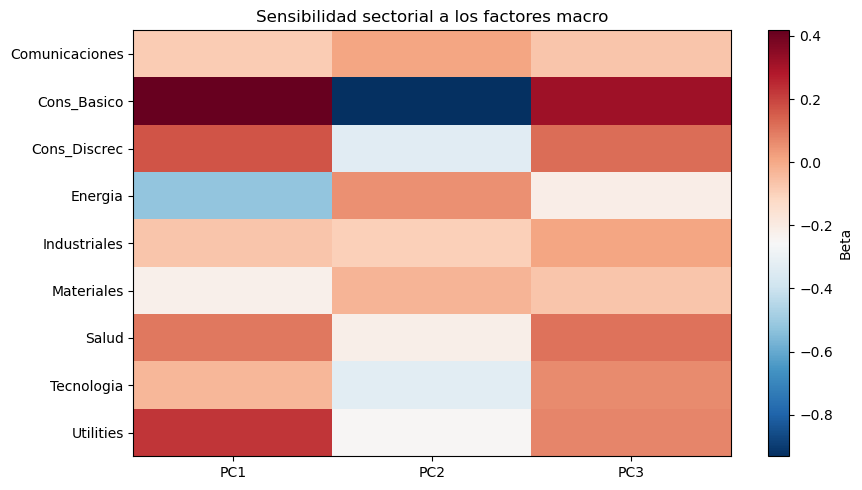

In [43]:
heat=betas_sector[beta_cols]

plt.figure(figsize=(9,5))
plt.imshow(
    heat,
    cmap="RdBu_r",
    aspect="auto"
)

plt.colorbar(label="Beta")
plt.xticks(
    range(len(beta_cols)),
    [x.replace("beta_","") for x in beta_cols]
)
plt.yticks(
    range(len(heat)),
    heat.index
)

plt.title("Sensibilidad sectorial a los factores macro")
plt.tight_layout()
plt.show()

### ¿Qué podemos aprender?

Si encontramos, por ejemplo:

$$
|\beta_{Industriales,PC1}|
>
|\beta_{Salud,PC1}|
$$

podemos concluir que el sector industrial presenta una mayor sensibilidad al factor macro representado por PC1.

La heterogeneidad sectorial aparece porque:

$$
\boxed{
\beta_i\neq\beta_j
}
$$

aunque ambos emisores estén expuestos a los mismos factores macroeconómicos.

Así, una recesión no modifica todas las PD en la misma proporción.

In [44]:
betas["R2"].describe()

count    52.000000
mean      0.112934
std       0.078951
min       0.003556
25%       0.047061
50%       0.098979
75%       0.166087
max       0.334217
Name: R2, dtype: float64

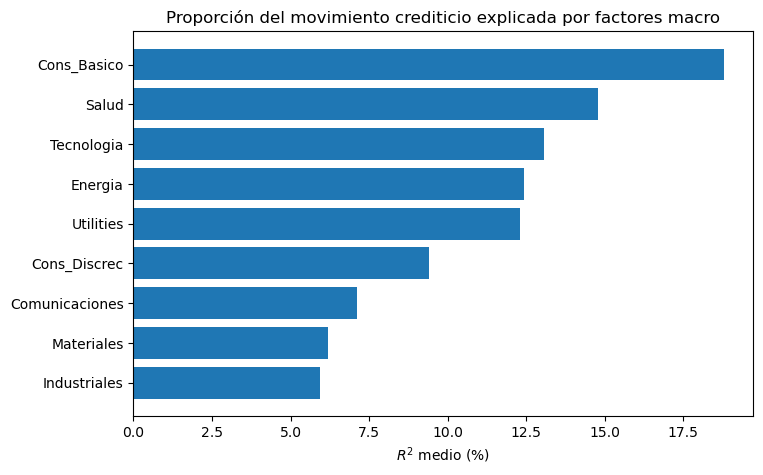

In [45]:
r2_sector=(
    betas.groupby("sector")["R2"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8,5))
plt.barh(r2_sector.index,100*r2_sector.values)
plt.xlabel(r"$R^2$ medio (%)")
plt.title("Proporción del movimiento crediticio explicada por factores macro")
plt.show()

## 5.4 Riesgo sistemático vs riesgo idiosincrático

El:

$$
R_i^2
$$

mide qué proporción de los movimientos de la calidad crediticia de la empresa está asociada a factores macro comunes.

Si:

$$
R_i^2=0.60
$$

aproximadamente el 60% de la variación histórica de:

$$
\Delta DD_i
$$

queda asociada a los factores macro utilizados.

El resto:

$$
1-R_i^2
$$

es riesgo no explicado por el modelo:

$$
\boxed{
\varepsilon_{i,t}
}
$$

Este componente puede incorporar:

- decisiones empresariales;
- litigios;
- cambios de gestión;
- shocks tecnológicos;
- problemas operativos;
- shocks sectoriales no incluidos;
- ruido.

## 5.5 Descomposición del riesgo de cada emisor

Ahora podemos escribir:

$$
\boxed{
\Delta DD_{i,t}
=
\underbrace{\beta_i'F_t}_{\text{riesgo sistemático}}
+
\underbrace{\varepsilon_{i,t}}_{\text{riesgo idiosincrático}}
}
$$

donde:

$$
F_t=
(PC_{1,t},\ldots,PC_{K,t})
$$

Esto explica por qué los deterioros crediticios pueden ocurrir conjuntamente.

Para dos empresas:

$$
i\neq j
$$

aunque:

$$
\varepsilon_i\perp\varepsilon_j
$$

ambas comparten:

$$
F_t
$$

Por tanto:

$$
Cov(\Delta DD_i,\Delta DD_j)\neq0
$$

si ambas tienen exposición a los mismos factores macroeconómicos.

In [46]:
residuos_df=pd.DataFrame(residuos).dropna()

print("Observaciones residuales:",len(residuos_df))
print("Emisores:",residuos_df.shape[1])

residuos_df.tail()

Observaciones residuales: 51
Emisores: 52


,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
2026-04-30,0.443305,-0.245615,0.220077,0.389579,0.926522,1.630427,0.447823,1.111878,0.426962,-0.473131,...,1.737434,0.306078,0.030084,0.577922,1.083060,0.117750,1.303198,2.577771,0.925786,-0.398305
2026-05-31,0.044017,-0.026974,0.269287,-0.166007,-0.215697,-0.216298,0.145752,-0.154073,-0.138138,0.087435,...,-0.150578,0.530705,0.018203,0.182616,-0.441671,0.095671,0.214838,-0.869446,-0.771865,-0.123465
2026-06-30,0.043208,0.018535,0.124810,-0.417539,-0.164767,-0.211723,-0.050374,-0.339201,-0.001421,-0.092282,...,-0.689073,-0.318425,-1.158325,0.116514,-0.212910,-0.948123,-0.567085,0.332837,-0.350313,0.023084
2026-07-31,-0.002984,0.068054,0.600288,0.123347,0.135704,-0.208350,-0.527379,-1.105047,-0.035795,-0.145300,...,-0.044298,-0.475523,-0.160606,0.002205,0.380785,-0.049143,-0.815737,-0.086789,0.240447,-0.049929
2026-08-31,0.087300,0.345808,0.120915,0.232032,0.130073,-0.244337,0.129429,-0.126813,-0.003611,0.226715,...,0.200088,-0.219937,0.084766,-0.068296,0.017425,0.035926,-0.433498,-0.329144,-0.168396,0.145204


## 5.6 ¿El modelo macro explica toda la dependencia?

No necesariamente.

Hemos modelado:

$$
\Delta DD_i
=
\beta_i'F+\varepsilon_i
$$

PCA captura la dependencia generada por factores macro comunes.

Pero todavía queda una pregunta:

> **¿Qué relación existe entre los shocks residuales de las empresas, especialmente durante episodios extremos?**

Podríamos asumir:

$$
\varepsilon_i\perp\varepsilon_j
$$

pero esta hipótesis puede ser demasiado fuerte.

En periodos normales la dependencia residual puede ser pequeña, pero durante una crisis pueden producirse deterioros conjuntos que un modelo Gaussiano no reproduce correctamente.

Por ello analizaremos ahora:

$$
\boxed{
(\varepsilon_1,\ldots,\varepsilon_N)
}
$$

mediante **cópulas**.

## 5.7 Lo que ya tenemos

### 1. Riesgo individual

Merton:

$$
\boxed{
E_i,\sigma_{E_i},D_i
\rightarrow
DD_i,PD_i
}
$$

### 2. Riesgo macroeconómico

PCA:

$$
\boxed{
X_{macro}
\rightarrow
PC_1,\ldots,PC_K
}
$$

### 3. Sensibilidad de cada empresa

Regresión:

$$
\boxed{
\Delta DD_i
=
\beta_i'PC+\varepsilon_i
}
$$

Ahora tenemos que modelar correctamente:

$$
\boxed{
\varepsilon_i
}
$$

y especialmente su comportamiento conjunto en situaciones extremas.

Ese será el papel de las:

$$
\boxed{\text{Cópulas}}
$$

# 6. Dependencia residual y cópulas

Hasta ahora hemos descompuesto el movimiento de la calidad crediticia como:

$$
\Delta DD_{i,t}
=
\beta_i'F_t
+
\varepsilon_{i,t}
$$

donde:

- $F_t$ recoge los factores macroeconómicos comunes;
- $\varepsilon_{i,t}$ recoge la parte no explicada por la macro.

Una primera posibilidad sería asumir:

$$
\varepsilon_i\perp\varepsilon_j
$$

Pero esto puede ser demasiado restrictivo.

Dos empresas pueden sufrir deterioros conjuntos por razones que no están completamente recogidas por nuestros factores macro:

- shocks sectoriales;
- shocks de liquidez;
- contagio financiero;
- eventos geopolíticos;
- deterioro simultáneo de expectativas.

Por tanto, necesitamos modelar la distribución conjunta de:

$$
\boxed{
(\varepsilon_1,\ldots,\varepsilon_N)
}
$$

y especialmente su comportamiento en la cola.

## 6.1 Correlación vs dependencia

Una matriz de correlaciones describe principalmente dependencia lineal:

$$
\rho_{ij}
=
Corr(\varepsilon_i,\varepsilon_j)
$$

Pero dos distribuciones pueden presentar una correlación similar y comportarse de forma muy diferente en escenarios extremos.

Por ejemplo:

- en periodos normales los residuos pueden presentar una correlación moderada;
- durante crisis pueden producirse deterioros simultáneos mucho más frecuentes.

Por tanto:

$$
\boxed{
\text{misma correlación}
\not\Rightarrow
\text{misma dependencia de cola}
}
$$

El Capital Económico depende precisamente de esas observaciones extremas.

Por ello utilizaremos cópulas.

## 6.2 ¿Qué hace una cópula?

Una cópula separa dos elementos:

### Distribuciones marginales

Para cada empresa:

$$
F_i(\varepsilon_i)
$$

### Estructura de dependencia

$$
C(u_1,\ldots,u_N)
$$

con:

$$
u_i=F_i(\varepsilon_i)
$$

Por el teorema de Sklar:

$$
\boxed{
F(\varepsilon_1,\ldots,\varepsilon_N)
=
C(
F_1(\varepsilon_1),
\ldots,
F_N(\varepsilon_N)
)
}
$$

Esto permite modelar por separado:

- cómo se comporta cada empresa;
- cómo se comportan conjuntamente.

## 6.3 De residuos a pseudo-observaciones

Las cópulas trabajan sobre variables uniformes:

$$
U_i\sim U(0,1)
$$

Transformamos los residuos mediante su distribución empírica:

$$
\boxed{
U_{i,t}
=
\frac{Rank(\varepsilon_{i,t})}
{T+1}
}
$$

De esta forma eliminamos la escala específica de cada empresa.

La información que queda es únicamente su estructura de dependencia.

In [47]:
from scipy.stats import rankdata
import numpy as np
import pandas as pd

U=pd.DataFrame(
    {
        col:rankdata(residuos_df[col])/(len(residuos_df)+1)
        for col in residuos_df.columns
    },
    index=residuos_df.index
)

U.head()

,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
2022-05-31,0.153846,0.711538,0.153846,0.365385,0.230769,0.096154,0.019231,0.576923,0.326923,0.942308,...,0.538462,0.942308,0.884615,0.192308,0.346154,0.923077,0.442308,0.019231,0.846154,0.903846
2022-06-30,0.115385,0.365385,0.038462,0.076923,0.134615,0.288462,0.942308,0.076923,0.057692,0.403846,...,0.096154,0.096154,0.461538,0.134615,0.576923,0.615385,0.192308,0.903846,0.057692,0.250000
2022-07-31,0.576923,0.769231,0.673077,0.865385,0.769231,0.807692,0.115385,0.826923,0.884615,0.096154,...,0.788462,0.750000,0.153846,0.500000,0.596154,0.076923,0.826923,0.576923,0.884615,0.750000
2022-08-31,0.750000,0.730769,0.884615,0.769231,0.634615,0.653846,0.923077,0.500000,0.769231,0.788462,...,0.673077,0.865385,0.711538,0.653846,0.730769,0.557692,0.423077,0.730769,0.557692,0.634615
2022-09-30,0.423077,0.653846,0.269231,0.461538,0.153846,0.134615,0.846154,0.365385,0.076923,0.134615,...,0.153846,0.115385,0.288462,0.307692,0.115385,0.230769,0.230769,0.923077,0.288462,0.230769


## 6.4 Dependencia mediante Kendall $\tau$

Para calibrar cópulas es útil utilizar medidas de rango.

Kendall mide concordancia:

$$
\tau
=
P(\text{concordancia})
-
P(\text{discordancia})
$$

Ventajas:

- no depende de la escala;
- es robusto frente a valores extremos;
- conecta directamente con parámetros de varias familias de cópulas.

Calcularemos la matriz:

$$
\boxed{
T=
[\tau_{ij}]
}
$$

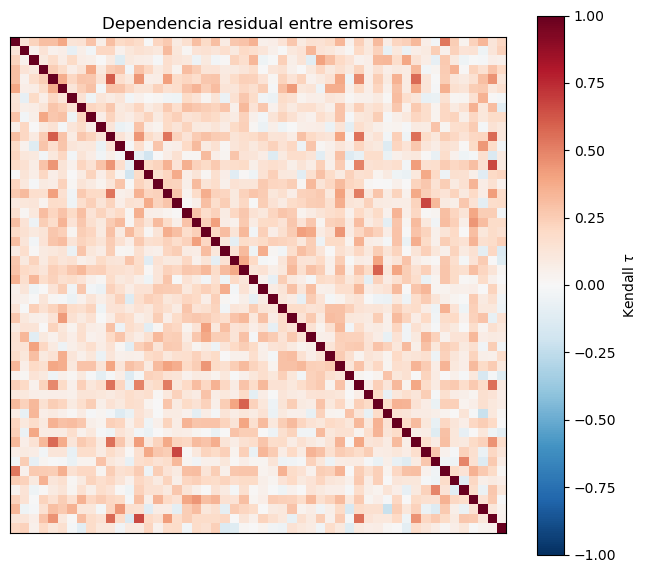

In [48]:
kendall=U.corr(method="kendall")

plt.figure(figsize=(8,7))
plt.imshow(kendall,cmap="RdBu_r",vmin=-1,vmax=1)
plt.colorbar(label=r"Kendall $\tau$")
plt.xticks([])
plt.yticks([])
plt.title("Dependencia residual entre emisores")
plt.show()

## 6.5 Matriz de correlación latente

Para las cópulas Gaussiana y Student-t existe una relación entre Kendall $\tau$ y la correlación latente:

$$
\boxed{
\rho_{ij}
=
\sin\left(
\frac{\pi}{2}\tau_{ij}
\right)
}
$$

Esto nos permite transformar la dependencia observada por rangos en una matriz de correlación compatible con la cópula.

In [49]:
R=np.sin(np.pi*kendall.values/2)
np.fill_diagonal(R,1.0)

eig=np.linalg.eigvalsh(R)

print("Autovalor mínimo:",eig.min())

Autovalor mínimo: -0.13501187567884965


In [50]:
def nearest_corr(R,eps=1e-6):
    R=(R+R.T)/2
    w,V=np.linalg.eigh(R)
    w=np.maximum(w,eps)
    R_pd=V@np.diag(w)@V.T
    d=np.sqrt(np.diag(R_pd))
    R_pd=R_pd/np.outer(d,d)
    np.fill_diagonal(R_pd,1.0)
    return R_pd

R=nearest_corr(R)

print("Autovalor mínimo corregido:",
      np.linalg.eigvalsh(R).min())

Autovalor mínimo corregido: 9.744827306985176e-07


## 6.6 Cópula Gaussiana

La cópula Gaussiana supone un vector latente:

$$
Z\sim N(0,R)
$$

y transforma:

$$
U_i=\Phi(Z_i)
$$

Tiene una propiedad importante:

$$
\boxed{
\lambda_L=\lambda_U=0
}
$$

Es decir, no presenta dependencia asintótica de cola.

Puede reproducir correlación en situaciones normales, pero tiende a infrarrepresentar la frecuencia de deterioros conjuntos muy extremos.

## 6.7 Cópula Student-t

La cópula Student-t utiliza:

$$
T\sim t_\nu(0,R)
$$

y:

$$
U_i=t_\nu(T_i)
$$

Comparte una estructura de correlación similar a la Gaussiana, pero incorpora un parámetro adicional:

$$
\nu
$$

que controla el grosor de las colas.

Para una correlación $\rho$:

$$
\boxed{
\lambda_L
=
2t_{\nu+1}
\left(
-\sqrt{
\frac{(\nu+1)(1-\rho)}
{1+\rho}
}
\right)
}
$$

y:

$$
\lambda_U=\lambda_L
$$

Por tanto:

$$
\boxed{
\nu\downarrow
\Rightarrow
\text{mayor dependencia de cola}
}
$$

### ¿Por qué la Student-t genera más eventos conjuntos?

Una representación de la t multivariante es:

$$
T=
\frac{Z}
{\sqrt{W/\nu}}
$$

donde:

$$
Z\sim N(0,R)
$$

y:

$$
W\sim\chi^2_\nu
$$

El término:

$$
\sqrt{\frac{\nu}{W}}
$$

es común a todas las empresas.

Cuando $W$ toma un valor pequeño:

$$
\sqrt{\frac{\nu}{W}}
\gg1
$$

todos los shocks se amplifican simultáneamente.

Ese mecanismo genera:

$$
\boxed{
\text{deterioros conjuntos extremos}
}
$$

que una cópula Gaussiana reproduce con mucha menor frecuencia.

In [51]:
from scipy.stats import multivariate_t
from scipy.stats import t as student_t
from scipy.stats import norm

def loglik_t_copula(U,R,nu):
    X=student_t.ppf(U.values,df=nu)

    joint=multivariate_t(
        loc=np.zeros(U.shape[1]),
        shape=R,
        df=nu
    ).logpdf(X)

    marginal=student_t.logpdf(
        X,
        df=nu
    ).sum(axis=1)

    return np.sum(joint-marginal)

nus=[3,4,5,6,8,10,15,20,30,50]

ll={nu:loglik_t_copula(U,R,nu) for nu in nus}

nu_opt=max(ll,key=ll.get)

print("nu seleccionado:",nu_opt)

nu seleccionado: 3


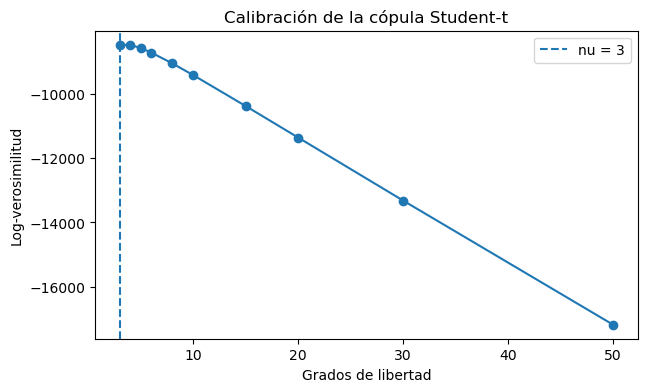

In [52]:
plt.figure(figsize=(7,4))
plt.plot(
    list(ll.keys()),
    list(ll.values()),
    marker="o"
)

plt.axvline(
    nu_opt,
    ls="--",
    label=f"nu = {nu_opt}"
)

plt.xlabel("Grados de libertad")
plt.ylabel("Log-verosimilitud")
plt.title("Calibración de la cópula Student-t")
plt.legend()
plt.show()

In [53]:
rho_media=R[np.triu_indices_from(R,k=1)].mean()

lambda_t=2*student_t.cdf(
    -np.sqrt(
        (nu_opt+1)*(1-rho_media)
        /(1+rho_media)
    ),
    df=nu_opt+1
)

print(f"Correlación latente media: {rho_media:.3f}")
print("Dependencia de cola Gaussiana: 0")
print(f"Dependencia de cola t: {lambda_t:.3f}")

Correlación latente media: 0.217
Dependencia de cola Gaussiana: 0
Dependencia de cola t: 0.184


In [54]:
idx=np.triu_indices_from(R,k=1)
pos=np.argmax(R[idx])

i=idx[0][pos]
j=idx[1][pos]

tk1=U.columns[i]
tk2=U.columns[j]

print("Par seleccionado:",tk1,tk2)
print("rho =",R[i,j])

Par seleccionado: DUK SO
rho = 0.8487037179315828


In [55]:
N=50_000
rng=np.random.default_rng(42)

rho=R[i,j]

R2=np.array([
    [1,rho],
    [rho,1]
])

# Gaussiana
Zg=rng.multivariate_normal(
    [0,0],
    R2,
    size=N
)

Ug=norm.cdf(Zg)

# Student-t
Z=rng.multivariate_normal(
    [0,0],
    R2,
    size=N
)

W=rng.chisquare(
    nu_opt,
    size=N
)

Tsim=Z/np.sqrt(
    W[:,None]/nu_opt
)

Ut=student_t.cdf(
    Tsim,
    df=nu_opt
)

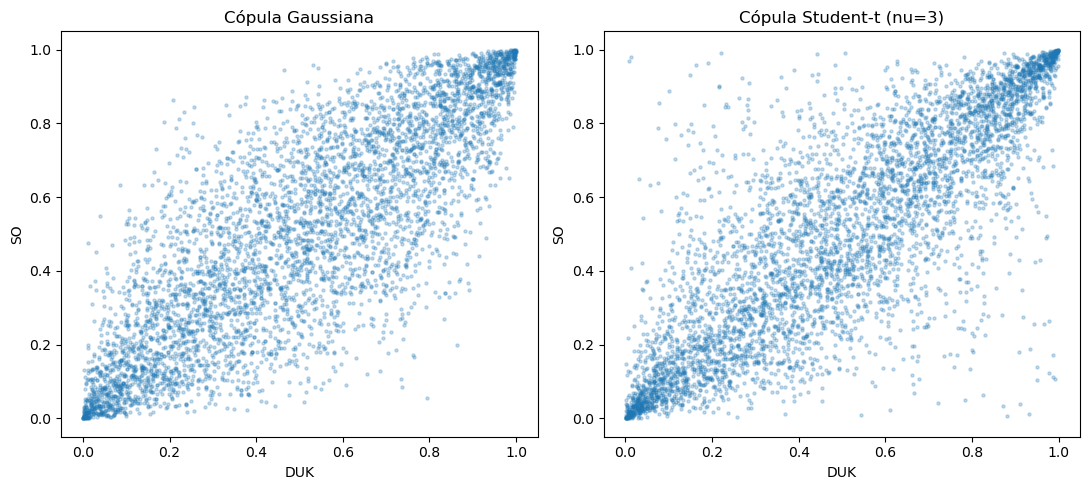

In [56]:
fig,ax=plt.subplots(1,2,figsize=(11,5))

ax[0].scatter(
    Ug[:5000,0],
    Ug[:5000,1],
    s=5,
    alpha=.25
)
ax[0].set_title("Cópula Gaussiana")
ax[0].set_xlabel(tk1)
ax[0].set_ylabel(tk2)

ax[1].scatter(
    Ut[:5000,0],
    Ut[:5000,1],
    s=5,
    alpha=.25
)
ax[1].set_title(
    f"Cópula Student-t (nu={nu_opt})"
)
ax[1].set_xlabel(tk1)
ax[1].set_ylabel(tk2)

plt.tight_layout()
plt.show()

In [57]:
q=0.05

joint_g=np.mean(
    (Ug[:,0]<q)
    &(Ug[:,1]<q)
)

joint_t=np.mean(
    (Ut[:,0]<q)
    &(Ut[:,1]<q)
)

print(f"P(U1<5%, U2<5%) Gaussiana: {joint_g:.3%}")
print(f"P(U1<5%, U2<5%) Student-t: {joint_t:.3%}")

P(U1<5%, U2<5%) Gaussiana: 2.886%
P(U1<5%, U2<5%) Student-t: 3.196%


## 6.8 Misma dependencia media, distinta pérdida extrema

La diferencia entre ambas cópulas no está principalmente en la Expected Loss.

Las probabilidades marginales de cada empresa seguirán siendo las mismas.

Por tanto:

$$
EL
=
\sum_iPD_iLGD_iEAD_i
$$

cambiará poco o nada.

Lo que cambia es la probabilidad de que muchas empresas se deterioren simultáneamente.

Por ello esperamos:

$$
EL_{Gauss}
\approx
EL_t
$$

pero:

$$
\boxed{
VaR_t>VaR_{Gauss}
}
$$

y especialmente:

$$
\boxed{
ES_t>ES_{Gauss}
}
$$

Por tanto:

$$
\boxed{
EC_t>EC_{Gauss}
}
$$

si la dependencia de cola es relevante.

## 6.9 Macro y cópula no deben contar dos veces la misma dependencia

Nuestro modelo tiene dos fuentes de dependencia:

### Dependencia sistemática

Proviene de los factores macroeconómicos:

$$
\beta_i'F_t
$$

### Dependencia residual

Proviene de:

$$
\varepsilon_{i,t}
$$

La cópula debe aplicarse sobre los **residuos**, no sobre los movimientos crediticios originales.

De lo contrario estaríamos incorporando dos veces la misma dependencia macroeconómica.

La estructura correcta es:

$$
\boxed{
\Delta DD_i
=
\beta_i'F
+
\varepsilon_i
}
$$

con:

$$
F
\sim
\text{factores macro PCA}
$$

y:

$$
(\varepsilon_1,\ldots,\varepsilon_N)
\sim
\text{cópula}
$$

## 6.10 Modelo conjunto de calidad crediticia

Ya podemos escribir el modelo que posteriormente simularemos:

$$
\boxed{
\Delta DD_i^{(m)}
=
\beta_i'F^{(m)}
+
\varepsilon_i^{(m)}
}
$$

donde:

$$
F^{(m)}
$$

representa un escenario macroeconómico y:

$$
\varepsilon^{(m)}
$$

se genera mediante una cópula multivariante.

Entonces:

$$
DD_i^{(m)}
=
DD_{i,0}
+
\Delta DD_i^{(m)}
$$

y:

$$
\boxed{
PD_i^{(m)}
=
\Phi(-DD_i^{(m)})
}
$$

Por tanto, cada escenario Monte Carlo generará una nueva situación crediticia para todos los emisores.

## 6.11 De la nueva DD al estado crediticio

El escenario:

$$
DD_i^{(m)}
$$

puede utilizarse de dos formas.

### Default Mode

Convertimos la DD en:

$$
PD_i^{(m)}
=
\Phi(-DD_i^{(m)})
$$

y simulamos:

$$
Default_i^{(m)}
$$

---

### Migration Mode

Utilizamos varios umbrales:

$$
c_{AAA},c_{AA},\ldots,c_D
$$

para convertir el estado latente en:

$$
Rating_i^{(m)}
$$

Así una empresa puede:

- mejorar;
- permanecer igual;
- sufrir downgrade;
- entrar en default.

Este será el enfoque más general para construir la distribución de pérdidas.

## 6.12 Lo que ya tenemos

Hemos construido cuatro piezas:

### 1. Merton

$$
E,\sigma_E,D
\rightarrow
DD,\ PD
$$

### 2. PCA macro

$$
X_{macro}
\rightarrow
F_1,\ldots,F_K
$$

### 3. Sensibilidades

$$
\Delta DD_i
=
\beta_i'F+\varepsilon_i
$$

### 4. Cópula

$$
(\varepsilon_1,\ldots,\varepsilon_N)
$$

con dependencia residual y, si utilizamos Student-t, dependencia de cola.

Ahora podemos unirlo todo en una simulación:

$$
\boxed{
\text{Monte Carlo}
}
$$

y generar la distribución completa de pérdidas de la cartera.

# 7. Monte Carlo: de la macroeconomía al default y al Capital Económico

En este bloque trabajaremos directamente con un horizonte de **un año**.

La lógica completa del modelo es:

$$
\boxed{
\text{Macro}
\rightarrow
\Delta DD^{12m}
\rightarrow
DD_T
\rightarrow
PD_T
\rightarrow
Default
\rightarrow
Pérdida
\rightarrow
Capital\ Económico
}
$$

Merton proporciona la situación crediticia inicial:

$$
DD_{i,0}\rightarrow PD_{i,0}
$$

El modelo macro modifica la calidad crediticia durante el año:

$$
\Delta DD_{i}^{12m}
=
\alpha_i+\beta_i'F^{12m}+\varepsilon_i
$$

La macro **no genera directamente el default**. Primero modifica la DD, después la PD y finalmente la PD determina la probabilidad de default.

## 7.1 Horizonte anual

El horizonte de Capital Económico es:

$$
T=1\text{ año}
$$

Por coherencia, no acumularemos doce shocks mensuales independientes. Construiremos directamente el cambio observado de la Distance to Default a doce meses:

$$
\boxed{
\Delta DD_{i,t}^{12m}=DD_{i,t}-DD_{i,t-12}
}
$$

y lo relacionaremos con las condiciones macroeconómicas predominantes durante esos mismos doce meses.

Así, en cada simulación generaremos **un escenario anual** y obtendremos directamente:

$$
DD_{i,T}^{(m)}=DD_{i,0}+\Delta DD_i^{12m,(m)}
$$

In [58]:
# Cambio anual observado de Distance to Default
delta_dd_12m=(
    dd_monthly
    -dd_monthly.shift(12)
).dropna(how="all")

print("Periodo ΔDD 12m:",delta_dd_12m.index.min(),"→",delta_dd_12m.index.max())
print("Empresas:",delta_dd_12m.shape[1])
delta_dd_12m.tail()

Periodo ΔDD 12m: 2023-04-30 00:00:00 → 2026-10-31 00:00:00
Empresas: 52


,AAL,ABT,AES,ALB,APA,BA,BHC,CAT,CC,CMCSA,...,SLB,SO,T,UAL,UPS,VZ,WDC,WMT,XOM,XRX
Date,,,,,,,,,,,,,,,,,,,,,
2026-06-30,0.289996,-4.197103,0.522863,0.511051,1.339631,1.524574,0.615483,0.907906,0.007806,-0.596314,...,1.031055,1.763015,-0.638192,0.945791,0.733707,-0.312634,1.115229,0.559262,0.677986,-0.983237
2026-07-31,0.361332,-3.275197,1.252231,0.722629,1.489944,1.186621,-0.161653,-0.628219,0.014117,-0.774133,...,1.239747,1.146733,-0.917596,0.946362,1.341369,-0.587532,-0.111710,-0.021763,0.859091,-0.729694
2026-08-31,0.442876,-3.568803,1.384944,0.667411,1.472433,0.621110,0.139504,-0.694025,-0.057251,-0.722689,...,1.296668,0.597784,-0.981789,0.709286,1.240533,-0.661178,-0.896045,-1.004252,0.304546,-0.633583
2026-09-30,0.443625,-4.005075,1.447891,0.411112,1.442829,0.238254,0.060617,-1.281392,-0.156666,-1.137336,...,0.738184,0.114917,-1.220102,0.692929,0.835609,-1.236032,-1.435022,-1.506850,0.173636,-0.622391
2026-10-31,0.443560,-3.774791,2.383657,0.363486,1.696182,0.414715,0.171051,-1.141058,0.029198,-0.881413,...,0.606529,0.210532,-0.483814,0.666766,0.711474,-0.692157,-1.442744,-0.998868,0.033618,-0.656190


## 7.2 Factor macroeconómico anual

Los factores PCA son mensuales. Para explicar un cambio crediticio a doce meses construiremos el estado macro del año como la media de los factores durante los últimos doce meses:

$$
\boxed{
F_t^{12m}=\frac{1}{12}\sum_{s=0}^{11}F_{t-s}
}
$$

Después estimaremos de nuevo las sensibilidades a la misma frecuencia:

$$
\boxed{
\Delta DD_{i,t}^{12m}
=
\alpha_i+\beta_i'F_t^{12m}+\varepsilon_{i,t}
}
$$

Esto evita mezclar betas mensuales con un horizonte anual.

In [59]:
macro_12m=(
    macro_factors
    .rolling(12)
    .mean()
    .dropna()
)

print("Periodo macro 12m:",macro_12m.index.min(),"→",macro_12m.index.max())
macro_12m.tail()

Periodo macro 12m: 2005-12-31 00:00:00 → 2026-08-31 00:00:00


,PC1,PC2,PC3
observation_date,,,
2026-04-30,-1.382799,-0.233145,-0.412387
2026-05-31,-1.424060,-0.189401,-0.356772
2026-06-30,-1.466520,-0.153354,-0.334756
2026-07-31,-1.491772,-0.137313,-0.320963
2026-08-31,-1.507271,-0.136356,-0.299147


## 7.3 Reestimación anual de sensibilidades macro

Como la variable dependiente ahora es:

$$
\Delta DD^{12m}
$$

reestimamos las betas utilizando también factores macro a doce meses.

El término:

$$
\beta_i'F_t^{12m}
$$

representará el componente **sistemático/macroeconómico** del cambio anual de calidad crediticia, mientras que:

$$
\varepsilon_{i,t}
$$

recogerá el componente residual.

In [60]:
resultados_beta_12m=[]
residuos_12m={}
factores_12m=macro_12m.columns.tolist()

for ticker in delta_dd_12m.columns:
    df=pd.concat([
        delta_dd_12m[ticker].rename("dDD"),
        macro_12m
    ],axis=1).dropna()

    if len(df)<24:
        continue

    y=df["dDD"].values
    X=df[factores_12m].values
    X_reg=np.column_stack([np.ones(len(X)),X])

    coef=np.linalg.lstsq(X_reg,y,rcond=None)[0]
    pred=X_reg@coef
    resid=y-pred

    ss_res=np.sum(resid**2)
    ss_tot=np.sum((y-y.mean())**2)
    r2=1-ss_res/ss_tot if ss_tot>0 else np.nan

    fila={
        "ticker":ticker,
        "sector":portfolio_model.loc[ticker,"sector"],
        "alpha":coef[0],
        "R2":r2,
        "n_obs":len(df)
    }
    for k,factor in enumerate(factores_12m):
        fila[f"beta_{factor}"]=coef[k+1]

    resultados_beta_12m.append(fila)
    residuos_12m[ticker]=pd.Series(resid,index=df.index)

betas_12m=pd.DataFrame(resultados_beta_12m).set_index("ticker")
residuos_12m_df=pd.DataFrame(residuos_12m)

print("Empresas con modelo anual:",len(betas_12m))
betas_12m.head()

Empresas con modelo anual: 52


,sector,alpha,R2,n_obs,beta_PC1,beta_PC2,beta_PC3
ticker,,,,,,,
AAL,Industriales,0.916281,0.533410,40,0.958152,-1.739227,1.344106
ABT,Salud,-17.527036,0.944854,40,-8.172541,-1.659742,-3.010984
AES,Utilities,-1.341339,0.142615,40,-0.898790,1.256290,-0.209504
ALB,Materiales,9.181730,0.683463,40,5.665843,-3.162998,3.458437
APA,Energia,-16.527665,0.348086,40,-10.489115,7.287657,-4.537440


In [61]:
# Universo común disponible para simulación
empresas=(
    betas_12m.index
    .intersection(residuos_12m_df.columns)
    .intersection(merton.index)
    .intersection(portfolio_model.index)
)

N=len(empresas)
print("Número de empresas simuladas:",N)

Número de empresas simuladas: 52


In [62]:
# Dependencia residual anual: Kendall por pares
resid_anual=residuos_12m_df[empresas]
kendall_12m=resid_anual.corr(method="kendall",min_periods=24)

# Si algún par no tiene suficientes observaciones, no imponemos dependencia residual
kendall_12m=kendall_12m.fillna(0.0)
np.fill_diagonal(kendall_12m.values,1.0)

R_12m=np.sin(np.pi*kendall_12m.values/2)
np.fill_diagonal(R_12m,1.0)
R_12m=nearest_corr(R_12m)

# Con pocos años efectivos, mantenemos el parámetro de cola calibrado en el bloque 6
nu_12m=nu_opt

print("nu Student-t utilizado:",nu_12m)
print("Autovalor mínimo R anual:",np.linalg.eigvalsh(R_12m).min())

nu Student-t utilizado: 3
Autovalor mínimo R anual: 9.676794139622727e-07


In [63]:
def cuantiles_empiricos(x,u):
    x=np.sort(np.asarray(x))
    q=np.linspace(0,1,len(x))
    return np.interp(u,q,x)

SEED=42
rng=np.random.default_rng(SEED)

# Bootstrap de un estado macro anual
F_hist_12m=macro_12m.values
idx_macro=rng.integers(0,len(F_hist_12m),size=N_SIM)
F_sim=F_hist_12m[idx_macro]

print("F_sim:",F_sim.shape)

F_sim: (200000, 3)


In [64]:
# Shock residual anual mediante t-copula
from scipy.stats import t as student_t

Z=rng.multivariate_normal(np.zeros(N),R_12m,size=N_SIM)
W=rng.chisquare(nu_12m,size=N_SIM)
Tsim=Z/np.sqrt(W[:,None]/nu_12m)
U_sim=student_t.cdf(Tsim,df=nu_12m)

eps_sim=np.empty((N_SIM,N))
for j,ticker in enumerate(empresas):
    hist=resid_anual[ticker].dropna().values
    eps_sim[:,j]=cuantiles_empiricos(hist,U_sim[:,j])

print("eps_sim:",eps_sim.shape)

eps_sim: (200000, 52)


In [65]:
beta_cols=[f"beta_{f}" for f in macro_12m.columns]

B=betas_12m.loc[empresas,beta_cols].values
alpha=betas_12m.loc[empresas,"alpha"].values
DD0=merton.loc[empresas,"DD"].values

print("Betas:",B.shape)
print("DD inicial:",DD0.shape)

Betas: (52, 3)
DD inicial: (52,)


## 7.4 La macro entra aquí: de $F^{12m}$ a $DD_T$

Para cada escenario $m$ calculamos:

$$
\boxed{
\Delta DD_i^{12m,(m)}
=
\alpha_i
+
\beta_i'F^{12m,(m)}
+
\varepsilon_i^{(m)}
}
$$

La parte macroeconómica es exactamente:

```python
sistematico = F_sim @ B.T
```

Después:

$$
\boxed{
DD_{i,T}^{(m)}=DD_{i,0}+\Delta DD_i^{12m,(m)}
}
$$

No acumulamos doce shocks independientes: simulamos directamente el cambio anual estimado.

In [66]:
# Componente sistemático generado por el escenario macro anual
sistematico=F_sim@B.T

# Cambio anual total de la Distance to Default
delta_DD=alpha+sistematico+eps_sim

# Distance to Default al final del horizonte de un año
DD_T=DD0+delta_DD

print("Dimensión DD_T:",DD_T.shape)
print("DD inicial media:",DD0.mean())
print("DD final media simulada:",DD_T.mean())

Dimensión DD_T: (200000, 52)
DD inicial media: 8.335867427448921
DD final media simulada: 2.116505592623805


## 7.5 De la DD del escenario a la Probability of Default

Para cada empresa y escenario:

$$
\boxed{
PD_i^{(m)}=\Phi(-DD_{i,T}^{(m)})
}
$$

Así, la PD deja de ser fija:

$$
PD_{i,0}\rightarrow PD_i^{(m)}
$$

Un escenario macro adverso que reduzca la DD aumenta la PD; uno favorable la reduce.

La cadena relevante es:

$$
\boxed{
Macro\rightarrow DD\rightarrow PD
}
$$

In [67]:
from scipy.stats import norm

PD_scenario=norm.cdf(-DD_T)
PD_scenario=np.clip(PD_scenario,PD_FLOOR,0.999)

pd_inicial=merton.loc[empresas,"PD"].values

print(f"PD media inicial:  {pd_inicial.mean():.3%}")
print(f"PD media simulada: {PD_scenario.mean():.3%}")

PD media inicial:  0.292%
PD media simulada: 29.382%


## 7.6 Diagnóstico de la simulación

Antes de generar defaults comprobamos que la distribución simulada sea interpretable.

No eliminamos escenarios extremos: son precisamente los que importan para el Capital Económico. Para que el histograma sea legible, el eje del gráfico de una empresa se limita al percentil 99.5%; **todos los escenarios** siguen utilizándose para calcular defaults, pérdidas, VaR y ES.

In [68]:
print(f"PD simulada p50:   {np.quantile(PD_scenario,.50):.3%}")
print(f"PD simulada p95:   {np.quantile(PD_scenario,.95):.3%}")
print(f"PD simulada p99:   {np.quantile(PD_scenario,.99):.3%}")
print(f"PD simulada p99.9: {np.quantile(PD_scenario,.999):.3%}")
print(f"P(DD_T < 0):       {np.mean(DD_T<0):.3%}")

PD simulada p50:   0.030%
PD simulada p95:   99.900%
PD simulada p99:   99.900%
PD simulada p99.9: 99.900%
P(DD_T < 0):       29.013%


Emisor: LUMN
PD inicial:        7.411%
PD media simulada: 13.754%
PD p95:            78.742%
PD p99:            99.788%


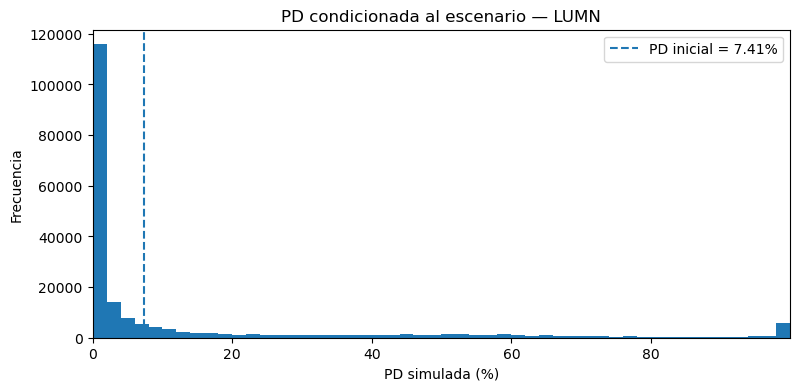

In [69]:
# Ejemplo: emisor con mayor PD inicial
j=int(np.argmax(pd_inicial))
ticker=empresas[j]

print("Emisor:",ticker)
print(f"PD inicial:        {pd_inicial[j]:.3%}")
print(f"PD media simulada: {PD_scenario[:,j].mean():.3%}")
print(f"PD p95:            {np.quantile(PD_scenario[:,j],.95):.3%}")
print(f"PD p99:            {np.quantile(PD_scenario[:,j],.99):.3%}")

p995=np.quantile(PD_scenario[:,j],.995)

plt.figure(figsize=(9,4))
plt.hist(PD_scenario[:,j]*100,bins=50)
plt.axvline(pd_inicial[j]*100,ls="--",label=f"PD inicial = {pd_inicial[j]:.2%}")
plt.xlim(0,max(p995*100,pd_inicial[j]*100*1.2,0.10))
plt.xlabel("PD simulada (%)")
plt.ylabel("Frecuencia")
plt.title(f"PD condicionada al escenario — {ticker}")
plt.legend()
plt.show()

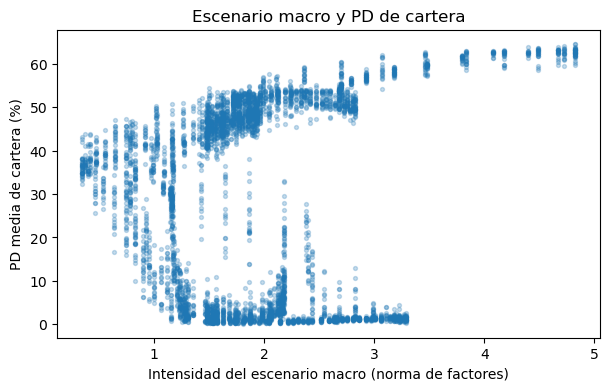

In [70]:
# Comprobación visual: relación entre shock macro y PD media del escenario
macro_intensidad=np.linalg.norm(F_sim,axis=1)
pd_media_escenario=PD_scenario.mean(axis=1)

muestra=np.linspace(0,N_SIM-1,min(5000,N_SIM),dtype=int)
plt.figure(figsize=(7,4))
plt.scatter(macro_intensidad[muestra],pd_media_escenario[muestra]*100,s=8,alpha=.25)
plt.xlabel("Intensidad del escenario macro (norma de factores)")
plt.ylabel("PD media de cartera (%)")
plt.title("Escenario macro y PD de cartera")
plt.show()

## 7.7 De la PD al evento de default

La PD es una probabilidad, no un default observado.

Condicionado al escenario simulamos:

$$
U_i^{(m)}\sim U(0,1)
$$

y definimos:

$$
\boxed{
D_i^{(m)}=1\{U_i^{(m)}<PD_i^{(m)}\}
}
$$

Por tanto:

$$
P(D_i^{(m)}=1\mid F^{(m)})=PD_i^{(m)}
$$

La macroeconomía influye en el default **a través de la PD**.

In [71]:
U_default=rng.random(PD_scenario.shape)
defaults=U_default<PD_scenario

print(f"Tasa de default simulada: {defaults.mean():.3%}")

Tasa de default simulada: 29.378%


In [72]:
default_rate_scenario=defaults.mean(axis=1)
num_defaults=defaults.sum(axis=1)

print(f"Defaults medios por escenario: {num_defaults.mean():.2f}")
print(f"Tasa default media: {default_rate_scenario.mean():.3%}")
print(f"Tasa default p95:   {np.quantile(default_rate_scenario,.95):.3%}")
print(f"Tasa default p99:   {np.quantile(default_rate_scenario,.99):.3%}")

Defaults medios por escenario: 15.28
Tasa default media: 29.378%
Tasa default p95:   59.615%
Tasa default p99:   63.462%


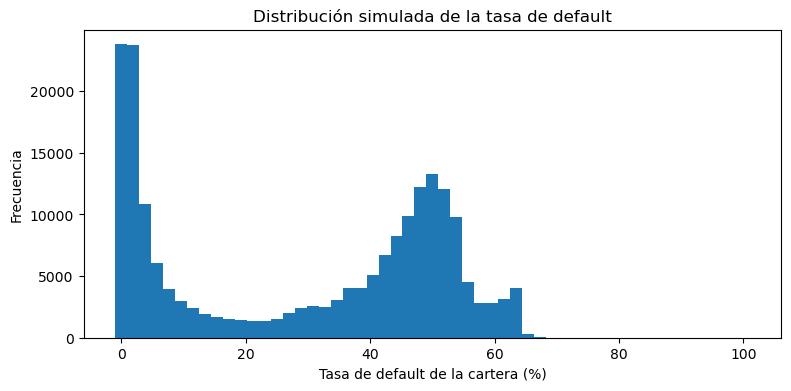

In [73]:
# La tasa de default solo puede tomar múltiplos de 1/N
paso=100/max(N,1)
bins=np.arange(-paso/2,100+1.5*paso,paso)

plt.figure(figsize=(9,4))
plt.hist(default_rate_scenario*100,bins=bins)
plt.xlabel("Tasa de default de la cartera (%)")
plt.ylabel("Frecuencia")
plt.title("Distribución simulada de la tasa de default")
plt.show()

In [74]:
EAD_vec=portfolio_model.loc[empresas,"EAD"].values
LGD_vec=portfolio_model.loc[empresas,"LGD"].values

loss_i=defaults*EAD_vec*LGD_vec
loss_portfolio=loss_i.sum(axis=1)

print(f"EAD total:     €{EAD_vec.sum()/1e6:,.2f} M")
print(f"Pérdida media: €{loss_portfolio.mean()/1e6:,.2f} M")

EAD total:     €5,200.00 M
Pérdida media: €687.44 M


## 7.8 EL, VaR, ES y Capital Económico

En Default Mode:

$$
L_i^{(m)}=EAD_i\times LGD_i\times D_i^{(m)}
$$

y:

$$
L^{(m)}=\sum_iL_i^{(m)}
$$

Sobre la distribución completa de pérdidas calculamos:

$$
EL=E[L],\qquad VaR_\alpha=q_\alpha(L)
$$

$$
ES_\alpha=E[L\mid L\ge VaR_\alpha]
$$

y:

$$
\boxed{
EC_\alpha=ES_\alpha-EL
}
$$

Así separamos la pérdida esperada del colchón frente a pérdidas inesperadas de cola.

In [75]:
def metricas_riesgo(loss,alpha=0.999):
    EL=loss.mean()
    VaR=np.quantile(loss,alpha)
    tail=loss[loss>=VaR]
    ES=tail.mean()
    return {
        "EL":EL,
        "VaR":VaR,
        "ES":ES,
        "EC_VaR":VaR-EL,
        "EC_ES":ES-EL
    }

metricas=metricas_riesgo(loss_portfolio,ALPHA)

for k,v in metricas.items():
    print(f"{k:8s}: €{v/1e6:,.2f} M")

EL      : €687.44 M
VaR     : €1,530.00 M
ES      : €1,532.96 M
EC_VaR  : €842.56 M
EC_ES   : €845.52 M


## 7.9 Distribución de pérdidas y RARORAC

La distribución de crédito es discreta porque, con EAD y LGD constantes, cada nuevo default añade el mismo salto de pérdida. Por eso el gráfico se construye con intervalos alineados con ese salto.

Una vez obtenido el Capital Económico evaluamos la rentabilidad ajustada al riesgo mediante:

$$
\boxed{
RARORAC=
\frac{Ingresos-Costes-EL}{Capital\ Económico}
}
$$

Como no disponemos de ingresos y costes reales de una cartera bancaria, utilizaremos un **margen neto antes de pérdidas** como supuesto editable sobre la EAD total.

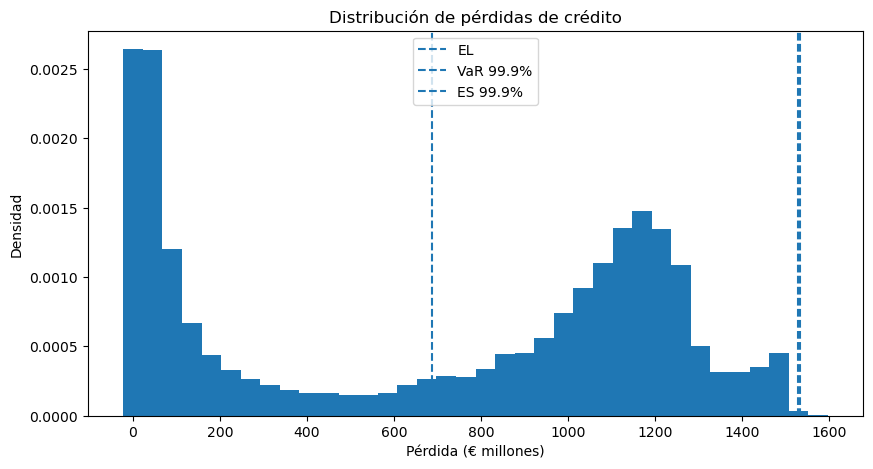

In [76]:
EL=metricas["EL"]
VaR=metricas["VaR"]
ES=metricas["ES"]
EC=metricas["EC_ES"]

step=(EAD_vec*LGD_vec).min() if len(EAD_vec)>0 else 1.0
max_loss=loss_portfolio.max()
bins=np.arange(-0.5*step,max_loss+1.5*step,step)

plt.figure(figsize=(10,5))
plt.hist(loss_portfolio/1e6,bins=bins/1e6,density=True)
plt.axvline(EL/1e6,ls="--",label="EL")
plt.axvline(VaR/1e6,ls="--",label=f"VaR {ALPHA:.1%}")
plt.axvline(ES/1e6,ls="--",label=f"ES {ALPHA:.1%}")
plt.xlabel("Pérdida (€ millones)")
plt.ylabel("Densidad")
plt.title("Distribución de pérdidas de crédito")
plt.legend()
plt.show()

In [77]:
resumen_capital=pd.DataFrame({
    "Métrica":["Expected Loss","VaR","Expected Shortfall","Capital Económico (ES-EL)"],
    "EUR_millones":[EL/1e6,VaR/1e6,ES/1e6,EC/1e6]
})

resumen_capital

,Métrica,EUR_millones
0,Expected Loss,687.437775
1,VaR,1530.000000
2,Expected Shortfall,1532.962382
3,Capital Económico (ES-EL),845.524607


In [78]:
# Supuestos editables para RARORAC
MARGEN_NETO_ANTES_PERDIDAS_PCT=0.03
HURDLE_RATE=0.15

EAD_TOTAL=EAD_vec.sum()
MARGEN_NETO_ANTES_PERDIDAS=MARGEN_NETO_ANTES_PERDIDAS_PCT*EAD_TOTAL
BENEFICIO_AJUSTADO=MARGEN_NETO_ANTES_PERDIDAS-EL
RARORAC=BENEFICIO_AJUSTADO/EC if EC>0 else np.nan

print(f"EAD total:                €{EAD_TOTAL/1e6:,.2f} M")
print(f"Margen antes pérdidas:    €{MARGEN_NETO_ANTES_PERDIDAS/1e6:,.2f} M")
print(f"Expected Loss:            €{EL/1e6:,.2f} M")
print(f"Capital Económico:        €{EC/1e6:,.2f} M")
print(f"RARORAC:                   {RARORAC:.2%}")
print(f"Hurdle rate:               {HURDLE_RATE:.2%}")
print("Supera hurdle:" , bool(RARORAC>HURDLE_RATE) if np.isfinite(RARORAC) else "No evaluable")

EAD total:                €5,200.00 M
Margen antes pérdidas:    €156.00 M
Expected Loss:            €687.44 M
Capital Económico:        €845.52 M
RARORAC:                   -62.85%
Hurdle rate:               15.00%
Supera hurdle: False


## 7.10 Lectura final del modelo

La arquitectura completa queda:

$$
\boxed{
\text{Datos de mercado}
\rightarrow Merton
\rightarrow DD_0,PD_0
}
$$

$$
\boxed{
\text{Macro}
\rightarrow PCA
\rightarrow F^{12m}
\rightarrow \Delta DD^{12m}
\rightarrow PD^{scenario}
}
$$

$$
\boxed{
PD^{scenario}
\rightarrow Default
\rightarrow Pérdidas
\rightarrow EL,VaR,ES,EC
}
$$

Finalmente:

$$
\boxed{
EC\rightarrow RARORAC
}
$$

El Capital Económico es una propiedad de la **distribución conjunta de pérdidas de la cartera**, no de una PD aislada.

### Resumen de la lógica

- **Merton** fija la calidad crediticia inicial.
- **PCA macro** resume el entorno económico.
- Las **betas anuales** trasladan el escenario macro a cambios en DD.
- La **t-copula** modela dependencia residual y de cola sin duplicar la dependencia macro.
- La DD simulada determina la **PD condicionada al escenario**.
- La PD genera defaults y, con EAD/LGD, la distribución de pérdidas.
- De esa distribución obtenemos **EL, VaR, ES y Capital Económico**.
- El **RARORAC** compara el beneficio ajustado por EL con el capital realmente consumido.